In [ ]:
try:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=True)
except ImportError:
    pass



Mounted at /content/drive


In [ ]:


# cell 0 installations 
!pip -q install hnswlib sentence-transformers lightgbm implicit
!pip -q install scikit-learn scipy tqdm pyarrow joblib psutil
print('install done')

# cell1  imports & GPU 
import os, re, gc, gzip, json, math, glob, random, warnings, time
from pathlib import Path
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor, as_completed
from typing import Dict, List, Optional, Tuple
import numpy as np
import pandas as pd
import scipy.sparse as sp
import torch
import hnswlib
import joblib
import lightgbm as lgb
import psutil
from tqdm.auto import tqdm
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import ndcg_score
from sentence_transformers import SentenceTransformer

warnings.filterwarnings('ignore')
tqdm.pandas()

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', DEVICE)
if DEVICE == 'cuda':
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.benchmark = True
    torch.set_float32_matmul_precision('high')
    p = torch.cuda.get_device_properties(0)
    print(f'GPU: {p.name} | VRAM: {p.total_memory/1e9:.0f}GB')

os.environ['TOKENIZERS_PARALLELISM'] = 'false'
os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'

def ram():
    cpu_gb = psutil.Process().memory_info().rss / 1e9
    msg = f'RAM: {cpu_gb:.1f}GB'
    if DEVICE == 'cuda':
        gpu_gb = torch.cuda.memory_allocated() / 1e9
        msg += f' | GPU: {gpu_gb:.1f}GB'
    print(msg)

ram(); print('imports done')

#  CELL2  paths 

RAW_DIR  = Path('/content/drive/MyDrive/new_project/data/raw')
NEW_BASE = Path('/content/drive/MyDrive/new_project/data/new_method')

PROC_DIR  = NEW_BASE / 'processed'
INT_DIR   = PROC_DIR / 'interactions'
EMBED_DIR = NEW_BASE / 'embeddings'
EMB_PARTS = EMBED_DIR / 'parts'
INDEX_DIR = NEW_BASE / 'indexes'
CF_DIR    = NEW_BASE / 'cf'
RNK_DIR   = NEW_BASE / 'reranker'
RNK_PARTS = RNK_DIR  / 'train_parts'
MEM_DIR   = NEW_BASE / 'memory'
LOCAL_DIR = Path('/content/local_cache')
LOCAL_PARTS = LOCAL_DIR / 'parts'

for d in [PROC_DIR, INT_DIR, EMBED_DIR, EMB_PARTS, INDEX_DIR, CF_DIR,
          RNK_DIR, RNK_PARTS, MEM_DIR, LOCAL_DIR, LOCAL_PARTS]:
    d.mkdir(parents=True, exist_ok=True)

CATALOG_RAW_FILE  = PROC_DIR / 'catalog.parquet'
CATALOG_FILE      = PROC_DIR / 'catalog_enriched.parquet'
INT_COMBINED_FILE = PROC_DIR / 'interactions_combined.parquet'
WORK_TEXTS_FILE   = PROC_DIR / 'work_texts.parquet'
TITLE_EMB_FILE    = EMBED_DIR / 'title_emb.npy'
DESC_EMB_FILE     = EMBED_DIR / 'desc_emb.npy'
COMBINED_EMB_FILE = EMBED_DIR / 'combined_emb.npy'
EMB_PROGRESS_FILE = EMBED_DIR / 'progress.json'
HNSW_INDEX_FILE   = INDEX_DIR / 'hnsw.bin'
TFIDF_VECT_FILE   = INDEX_DIR / 'tfidf_vect.joblib'
TFIDF_MAT_FILE    = INDEX_DIR / 'tfidf_mat.npz'
ALS_USER_FILE     = CF_DIR / 'user_factors.npy'
ALS_ITEM_FILE     = CF_DIR / 'item_factors.npy'
ALS_ITEM_MAP_FILE = CF_DIR / 'book_id_to_idx.json'
ALS_USER_MAP_FILE = CF_DIR / 'user_id_to_idx.json'
TRAIN_DATA_FILE   = RNK_DIR / 'train_data.parquet'
EVAL_DATA_FILE    = RNK_DIR / 'eval_data.parquet'
TRAIN_FEATS_FILE  = RNK_DIR / 'train_feats.parquet'
EVAL_FEATS_FILE   = RNK_DIR / 'eval_feats.parquet'
FEAT_COLS_FILE    = RNK_DIR / 'feature_cols.json'
MODEL_FILE        = RNK_DIR / 'lgbm_reranker.txt'
MODEL_CKPT_FILE   = RNK_DIR / 'lgbm_checkpoint.txt'
MODEL_CKPT_META   = RNK_DIR / 'lgbm_checkpoint_meta.json'
EVAL_RESULTS_FILE = RNK_DIR / 'eval_results.json'
MEMORY_FILE       = MEM_DIR / 'user_memory.json'
PIPELINE_STATE    = NEW_BASE / 'pipeline_state.json'
TRAIN_WIDS_FILE   = RNK_DIR / 'train_wids.json'
EVAL_WIDS_FILE    = RNK_DIR / 'eval_wids.json'

INT_FILES = {
    'children':    'goodreads_interactions_children.json.gz',
    'comics':      'goodreads_interactions_comics_graphic.json.gz',
    'fantasy':     'goodreads_interactions_fantasy_paranormal.json.gz',
    'history':     'goodreads_interactions_history_biography.json.gz',
    'mystery':     'goodreads_interactions_mystery_thriller_crime.json.gz',
    'poetry':      'goodreads_interactions_poetry.json.gz',
    'romance':     'goodreads_interactions_romance.json.gz',
    'young_adult': 'goodreads_interactions_young_adult.json.gz',
}
BOOK_FILES_GENRE = [
    'goodreads_books_fantasy_paranormal.json.gz',
    'goodreads_books_mystery_thriller_crime.json.gz',
    'goodreads_books_romance.json.gz',
    'goodreads_books_young_adult.json.gz',
    'goodreads_books_history_biography.json.gz',
    'goodreads_books_children.json.gz',
    'goodreads_books_comics_graphic.json.gz',
    'goodreads_books_poetry.json.gz',
]

def show_progress():
    checks = [
        ('Catalog (raw)',      CATALOG_RAW_FILE),
        ('Interactions',       INT_COMBINED_FILE),
        ('Catalog (enriched)', CATALOG_FILE),
        ('Work texts',         WORK_TEXTS_FILE),
        ('Embeddings',         TITLE_EMB_FILE),
        ('HNSW index',         HNSW_INDEX_FILE),
        ('ALS model',          ALS_ITEM_FILE),
        ('Train data',         TRAIN_DATA_FILE),
        ('Train features',     TRAIN_FEATS_FILE),
        ('LightGBM model',     MODEL_FILE),
    ]
    print(f'\nPipeline progress (base: {NEW_BASE}):')
    for name, f in checks:
        print(f'  {"yes" if f.exists() else "no "} {name}')

show_progress()

# cell3  helpers


def atomic_json(obj, path):
    p = Path(path); tmp = p.parent / (p.name + '.tmp')
    tmp.write_text(json.dumps(obj, indent=2, ensure_ascii=False)); tmp.replace(p)

def atomic_parquet(df, path):
    p = Path(path); tmp = p.parent / (p.name + '.tmp')
    df.to_parquet(tmp, index=False); tmp.replace(p)

def atomic_npy(arr, path):
    p = Path(path); tmp = p.parent / (p.name + '.tmp.npy')
    np.save(str(tmp), arr); tmp.replace(p)

def save_ckpt(stage, **meta):
    atomic_json({'stage': stage, 'ts': pd.Timestamp.utcnow().isoformat(), **meta}, PIPELINE_STATE)
    print(f'checkpoint: {stage}')

def flush(verbose=False):
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    if verbose: ram()

def open_jsonl(path: Path):
    if str(path).endswith('.gz'):
        return gzip.open(path, 'rt', encoding='utf-8', errors='replace')
    return open(path, 'r', encoding='utf-8', errors='replace')

def find_file(*names) -> Optional[Path]:
    for name in names:
        for variant in [name, name + '.gz']:
            p = RAW_DIR / variant
            if p.exists(): return p
    return None

MISS = {'', 'null', 'none', 'nan', 'na', 'n/a', '-', 'nil'}

def norm(x) -> str:
    if x is None: return ''
    s = str(x).strip()
    return '' if s.lower() in MISS else s

def tokenize(text) -> list:
    return re.findall(r"\b[\w\-']+\b", norm(text).lower())

def jaccard(a, b) -> float:
    A, B = set(a), set(b)
    if not A and not B: return 0.0
    return len(A & B) / max(1, len(A | B))

GENRE_ALIASES = {
    'sci fi': 'science fiction', 'sci-fi': 'science fiction', 'scifi': 'science fiction',
    'ya': 'young adult', 'historical': 'historical fiction',
    'dark-fantasy': 'dark fantasy', 'epic-fantasy': 'epic fantasy',
    'high-fantasy': 'high fantasy', 'urban-fantasy': 'urban fantasy',
    'graphic novel': 'graphic novels', 'chick-lit': 'literary fiction',
    'chick lit': 'literary fiction', 'paranormal romance': 'romance',
}
CURATED_GENRES = {
    'fantasy', 'dark fantasy', 'epic fantasy', 'high fantasy', 'urban fantasy',
    'science fiction', 'horror', 'romance', 'mystery', 'thriller', 'young adult',
    'historical fiction', 'historical fantasy', 'space opera', 'paranormal',
    'grimdark', 'non-fiction', 'biography', 'literary fiction', 'graphic novels',
    'children', 'poetry', 'self-help', 'psychology', 'philosophy', 'crime',
    'dystopian', 'adventure', 'classics', 'comedy', 'drama',
}
_NOISY = re.compile(
    r'^(to-read|currently-reading|read.*|owned.*|wish.*|want.*|borrowed|default|'
    r'library.*|arc.*|ebook.*|kindle.*|audible.*|reviewed.*|fav(ou?rite)?.*|'
    r'books?-i-.*|i-own.*|unfinished.*|did-not-finish|series|book-series|'
    r'novels?|fiction|books?|\d{4}.*)$'
)

def canon_genre(t: str) -> str:
    t = re.sub(r'\s+', ' ', norm(t).lower().replace('—', '-').replace('–', '-')).strip()
    return GENRE_ALIASES.get(t, t) if t else ''

def shelves_to_genres(shelves_raw) -> str:
    if not shelves_raw: return ''
    if isinstance(shelves_raw, str):
        try: shelves_raw = json.loads(shelves_raw.replace("'", '"'))
        except: return ''
    if not isinstance(shelves_raw, list): return ''
    seen: Dict[str, int] = {}
    for s in shelves_raw:
        name = norm(s.get('name', '') if isinstance(s, dict) else str(s)).lower()
        cnt = int(s.get('count', 1) if isinstance(s, dict) else 1)
        if _NOISY.match(name): continue
        g = canon_genre(name.replace('-', ' '))
        if g in CURATED_GENRES:
            if g not in seen or cnt > seen[g]: seen[g] = cnt
    return '|'.join(g for g, _ in sorted(seen.items(), key=lambda x: -x[1])[:3])

def parse_author_id(val) -> str:
    if val is None: return ''
    if isinstance(val, list):
        for item in val:
            if isinstance(item, dict): return norm(item.get('author_id', ''))
        return ''
    try:
        p = json.loads(str(val).replace("'", '"'))
        if isinstance(p, list) and p: return norm(p[0].get('author_id', ''))
    except: pass
    return ''

def parse_series_id(val) -> str:
    if val is None: return ''
    if isinstance(val, list): return norm(str(val[0])) if val else ''
    try:
        p = json.loads(str(val).replace("'", '"'))
        if isinstance(p, list) and p: return norm(str(p[0]))
    except: pass
    s = norm(str(val))
    return s if s.isdigit() else ''

print('helpers loaded')


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 70.3/70.3 kB 8.5 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
install done
Device: cuda
GPU: NVIDIA L4 | VRAM: 24GB
RAM: 1.2GB | GPU: 0.0GB
imports done

Pipeline progress (base: /content/drive/MyDrive/new_project/data/new_method):
  yes Catalog (raw)
  yes Interactions
  yes Catalog (enriched)
  yes Work texts
  yes Embeddings
  yes HNSW index
  yes ALS model
  yes Train data
  yes Train features
  yes LightGBM model
helpers loaded


In [ ]:

# CELL4  encoder 

EMBED_DIM   = 384
EMBED_BATCH = 512 if DEVICE == 'cuda' else 32

def _resolve_model():
    local = Path('/content/drive/MyDrive/hf_models/bge-small-en-v1.5')
    return str(local) if local.exists() else 'BAAI/bge-small-en-v1.5'

encoder = SentenceTransformer(_resolve_model(), device=DEVICE)
encoder.max_seq_length = 256
print(f'Encoder: {_resolve_model()}')

def encode(texts, bs=EMBED_BATCH, normalize=True) -> np.ndarray:
    if isinstance(texts, str): texts = [texts]
    texts = [str(t) if t is not None else '' for t in texts]
    if not texts: return np.empty((0, EMBED_DIM), dtype=np.float32)
    for b in [bs, max(64, bs // 2), 64, 32, 8]:
        try:
            with torch.inference_mode():
                out = encoder.encode(
                    texts, batch_size=b, device=DEVICE,
                    normalize_embeddings=normalize,
                    convert_to_numpy=True, show_progress_bar=False
                )
            return np.asarray(out, dtype=np.float32)
        except RuntimeError as e:
            if 'out of memory' not in str(e).lower(): raise
            flush()
    raise RuntimeError('OOM at all batch sizes')

ram()


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/133M [00:00<?, ?B/s]

... (4 outputs left out)

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Encoder: BAAI/bge-small-en-v1.5
RAM: 1.3GB | GPU: 0.1GB


In [ ]:

# cell5 — process books 

FORCE_BOOKS = False
BOOK_CHUNK  = 150_000  # row hrr ek chunk mei 

catalog = None

if CATALOG_RAW_FILE.exists() and not FORCE_BOOKS:
    catalog = pd.read_parquet(CATALOG_RAW_FILE)
    print(f'Catalog loaded: {len(catalog):,} works')
else:
    # columns jo rkhne h
    KEEP_RAW = {
        'book_id', 'work_id', 'title', 'description', 'average_rating',
        'ratings_count', 'text_reviews_count', 'num_pages', 'publication_year',
        'language_code', 'authors', 'series', 'popular_shelves', 'is_ebook',
    }

    def _clean_chunk(rows: list) -> pd.DataFrame:
        """Clean a list of raw dicts. Returns a small clean DataFrame."""
        df = pd.DataFrame(rows)
        df.columns = [c.lower() for c in df.columns]
        # columns delete kar od jo keep_row mei nhi h
        df = df[[c for c in df.columns if c in KEEP_RAW]]
    
        for c in ['average_rating', 'ratings_count', 'text_reviews_count', 'num_pages', 'publication_year']:
            if c in df.columns: df[c] = pd.to_numeric(df[c], errors='coerce')
        #km se km ek title and id
        if 'title' in df.columns:
            df['title'] = df['title'].where(df['title'].notna(), '').astype(str).str.strip()
            df = df[df['title'].str.len() > 0]
        for id_col in ['work_id', 'book_id']:
            if id_col in df.columns:
                df[id_col] = df[id_col].where(df[id_col].notna(), '').astype(str).str.strip()
                df = df[df[id_col].str.len() > 0]
                break
        # Parse nested columns
        if 'authors' in df.columns:
            df['author_id'] = df['authors'].apply(parse_author_id)
            df = df.drop(columns=['authors'])
        if 'series' in df.columns:
            df['series_id'] = df['series'].apply(parse_series_id)
            df = df.drop(columns=['series'])
        if 'popular_shelves' in df.columns:
            df['genres_shelves'] = df['popular_shelves'].apply(shelves_to_genres)
            df = df.drop(columns=['popular_shelves'])
        if 'description' in df.columns:
            df['description'] = df['description'].where(df['description'].notna(), '').astype(str)
        return df.reset_index(drop=True)

    def _stream_and_clean(path: Path) -> pd.DataFrame:
        """Stream a JSONL file in chunks, clean each, concatenate."""
        print(f'  Streaming: {path.name}')
        chunk_rows = []
        cleaned_parts = []
        total = 0
        with open_jsonl(path) as f:
            for line in f:
                try:
                    r = json.loads(line)
                    # sirf zaroori keys rkho
                    chunk_rows.append({k: r[k] for k in KEEP_RAW if k in r})
                except: continue
                if len(chunk_rows) >= BOOK_CHUNK:
                    cleaned_parts.append(_clean_chunk(chunk_rows))
                    total += len(chunk_rows)
                    print(f'    {total:,} rows streamed...')
                    chunk_rows = []
        if chunk_rows:
            cleaned_parts.append(_clean_chunk(chunk_rows))
        if not cleaned_parts: return pd.DataFrame()
        result = pd.concat(cleaned_parts, ignore_index=True)
        del cleaned_parts; flush()
        return result

    print('Stage 1: Processing books catalog...')

    main_path = find_file('goodreads_books.json')
    if main_path:
        df = _stream_and_clean(main_path)
    else:
        print('  Main file not found — merging genre subsets')
        parts = []
        for fname in BOOK_FILES_GENRE:
            p = find_file(fname)
            if not p: print(f'    skip: {fname}'); continue
            sub = _stream_and_clean(p)
            parts.append(sub)
            del sub; flush()
        if not parts: raise FileNotFoundError(f'No book files in {RAW_DIR}')
        df = pd.concat(parts, ignore_index=True)
        del parts; flush()

    if df.empty:
        print(' No books loaded. Check RAW_DIR:', RAW_DIR)
    else:
        # dedup best row per work_id
        id_col = 'work_id' if 'work_id' in df.columns else 'book_id'
        if 'ratings_count' in df.columns:
            df = df.sort_values('ratings_count', ascending=False)
        df = df.drop_duplicates(id_col, keep='first').reset_index(drop=True)
        atomic_parquet(df, CATALOG_RAW_FILE)
        save_ckpt('stage1_catalog', n=len(df))
        catalog = df
        del df; flush(verbose=True)
        print(f'Catalog saved: {len(catalog):,} works')

if catalog is not None:
    print(f'   Desc coverage:   {(catalog.get("description", pd.Series([""])) != "").mean():.1%}')
    print(f'   Rating coverage: {catalog.get("average_rating", pd.Series([np.nan])).notna().mean():.1%}')
    ram()

✅ Catalog loaded: 1,521,957 works
   Desc coverage:   77.0%
   Rating coverage: 100.0%
RAM: 3.4GB | GPU: 0.1GB


In [ ]:


# Cell6 — Process Interactions
FORCE_INT   = False
INT_CHUNK   = 1_000_000  # rows hrr ek chunk per genre

interactions = None

if INT_COMBINED_FILE.exists() and not FORCE_INT:
    interactions = pd.read_parquet(INT_COMBINED_FILE)
    print(f'Interactions loaded: {len(interactions):,} rows')
    print(f'   Users: {interactions.user_id.nunique():,} | Books: {interactions.book_id.nunique():,}')
else:
    print('Stage 2: Processing interactions (one genre at a time)...')
    saved_genre_paths = []

    for genre, fname in INT_FILES.items():
        out_path = INT_DIR / f'{genre}.parquet'

        if out_path.exists() and not FORCE_INT:
            print(f' {genre}: already saved')
            saved_genre_paths.append(out_path)
            continue

        path = find_file(fname)
        if not path:
            print(f' {genre}: not found, skip')
            continue

        print(f'  Processing {genre}: {path.name}...')
        chunk_dfs = []
        chunk_rows = []

        with open_jsonl(path) as f:
            for line in tqdm(f, desc=f'    {genre}', mininterval=10):
                try:
                    r = json.loads(line)
                    book_id_raw = r.get('book_id')
                    if book_id_raw is None: continue
                    chunk_rows.append({
                        'user_id':  str(r.get('user_id', '')),
                        'book_id':  int(book_id_raw),
                        'is_read':  bool(r.get('is_read', False)),
                        'rating':   int(r.get('rating', 0)),
                    })
                except: continue

                if len(chunk_rows) >= INT_CHUNK:
                    cdf = pd.DataFrame(chunk_rows)
                    cdf = cdf[cdf['user_id'].str.len() > 0]
                    chunk_dfs.append(cdf)
                    chunk_rows = []

        # last chunk
        if chunk_rows:
            cdf = pd.DataFrame(chunk_rows)
            cdf = cdf[cdf['user_id'].str.len() > 0]
            chunk_dfs.append(cdf)
        del chunk_rows

        if not chunk_dfs:
            print(f'  no valid rows for {genre}')
            continue

        # Concat chunks for this genre
        gdf = pd.concat(chunk_dfs, ignore_index=True)
        del chunk_dfs; flush()

        #  keep highest rating onlyy
        gdf = gdf.sort_values('rating', ascending=False)
        gdf = gdf.drop_duplicates(['user_id', 'book_id'], keep='first').reset_index(drop=True)

        atomic_parquet(gdf, out_path)
        n = len(gdf)
        del gdf; flush() 
        saved_genre_paths.append(out_path)
        print(f'    → {n:,} rows saved. ', end='')
        ram()

    if not saved_genre_paths:
        print('No interaction files — CF disabled')
        interactions = pd.DataFrame(columns=['user_id', 'book_id', 'is_read', 'rating'])
    else:
        # Combine karo hrr ek parquet ko 
        
        print(f'  Combining {len(saved_genre_paths)} genre files...')
        all_parts = []
        for p in saved_genre_paths:
            part = pd.read_parquet(p)
            all_parts.append(part)
            del part

        combined = pd.concat(all_parts, ignore_index=True)
        del all_parts; flush()

        print(f'  Pre-dedup: {len(combined):,} rows')
        combined = combined.sort_values('rating', ascending=False)
        combined = combined.drop_duplicates(['user_id', 'book_id'], keep='first').reset_index(drop=True)

        atomic_parquet(combined, INT_COMBINED_FILE)
        save_ckpt('stage2_interactions', n=len(combined))
        interactions = combined
        del combined; flush(verbose=True)
        interactions = pd.read_parquet(INT_COMBINED_FILE)  

    print(f' Interactions: {len(interactions):,} rows')
    if len(interactions) > 0:
        print(f'   Unique users: {interactions.user_id.nunique():,}')
        print(f'   Unique books: {interactions.book_id.nunique():,}')
        print(f'   is_read: {interactions.is_read.sum():,} | rated: {(interactions.rating>0).sum():,}')
    ram()

✅ Interactions loaded: 169,989,524 rows
   Users: 856,055 | Books: 1,244,608


In [ ]:

# cell7 — enrich catalog
FORCE_ENRICH = False

if CATALOG_FILE.exists() and not FORCE_ENRICH:
    catalog = pd.read_parquet(CATALOG_FILE)
    print(f'Enriched catalog loaded: {len(catalog):,} works, {len(catalog.columns)} cols')
elif catalog is None:
    print('catalog is None — run Cell 5 first')
else:
    print('Stage 3: Enriching catalog...')
    df = catalog.copy()

    #  Genre labels 
    p = find_file('goodreads_book_genres_initial.json')
    if p:
        print('  Loading genre labels...')
        g_rows = []
        with open_jsonl(p) as f:
            for line in f:
                try:
                    r = json.loads(line)
                    bid = norm(str(r.get('book_id', '')))
                    gd = r.get('genres', {})
                    if bid and isinstance(gd, dict) and gd:
                        top = max(gd.items(), key=lambda x: int(x[1]))[0]
                        g_rows.append({'book_id': bid, 'genre_label': canon_genre(top.split(',')[0].strip())})
                except: continue
        if g_rows and 'book_id' in df.columns:
            gdf = pd.DataFrame(g_rows).drop_duplicates('book_id')
            df = df.merge(gdf, on='book_id', how='left')
            print(f'    Genre coverage: {df.genre_label.notna().mean():.1%}')
        del g_rows; flush()

    #  Author names
    p = find_file('goodreads_book_authors.json')
    if p:
        print('  Loading author names...')
        a_rows = []
        with open_jsonl(p) as f:
            for line in f:
                try:
                    r = json.loads(line)
                    a_rows.append({
                        'author_id': norm(str(r.get('author_id', ''))),
                        'author_name': norm(str(r.get('name', ''))),
                    })
                except: continue
        if a_rows and 'author_id' in df.columns:
            adf = pd.DataFrame(a_rows).drop_duplicates('author_id')
            df = df.merge(adf, on='author_id', how='left')
            print(f'    Author coverage: {df.author_name.notna().mean():.1%}')
        del a_rows; flush()

    #  Series titles 
    p = find_file('goodreads_book_series.json')
    if p:
        print('  Loading series info...')
        s_rows = []
        with open_jsonl(p) as f:
            for line in f:
                try:
                    r = json.loads(line)
                    s_rows.append({
                        'series_id': norm(str(r.get('series_id', ''))),
                        'series_title': norm(str(r.get('title', ''))),
                    })
                except: continue
        if s_rows and 'series_id' in df.columns:
            sdf = pd.DataFrame(s_rows).drop_duplicates('series_id')
            df = df.merge(sdf, on='series_id', how='left')
        del s_rows; flush()

    #  Works
    p = find_file('goodreads_book_works.json')
    if p and 'work_id' in df.columns:
        print('  Loading works data...')
        w_rows = []
        with open_jsonl(p) as f:
            for line in f:
                try:
                    r = json.loads(line)
                    w_rows.append({
                        'work_id': norm(str(r.get('work_id', ''))),
                        'work_pub_year': pd.to_numeric(r.get('original_publication_year'), errors='coerce'),
                    })
                except: continue
        if w_rows:
            wdf = pd.DataFrame(w_rows).drop_duplicates('work_id')
            df = df.merge(wdf, on='work_id', how='left')
            if 'publication_year' in df.columns:
                df['publication_year'] = df['publication_year'].fillna(df['work_pub_year'])
            df = df.drop(columns=['work_pub_year'], errors='ignore')
        del w_rows; flush()

  
    cols_to_try = ['genres_shelves', 'genre_label']
    df['final_genre'] = ''
    for c in reversed(cols_to_try):  
        if c in df.columns:
            filled = df[c].fillna('').astype(str).str.strip()
            df['final_genre'] = np.where(filled != '', filled, df['final_genre'])

    #  interaction count hrr book ka
    if interactions is not None and len(interactions) > 0 and 'book_id' in df.columns:
        print('  Adding interaction stats...')
        stats = interactions.groupby('book_id').agg(
            n_interactions=('user_id', 'count'),
            n_reads=('is_read', 'sum'),
        ).reset_index()
        df['book_id'] = pd.to_numeric(df['book_id'], errors='coerce')
        df = df.merge(stats, on='book_id', how='left')
        df['n_interactions'] = df['n_interactions'].fillna(0).astype(int)
        df['n_reads'] = df['n_reads'].fillna(0).astype(int)
        del stats; flush()

    atomic_parquet(df, CATALOG_FILE)
    save_ckpt('stage3_enriched', n=len(df))
    catalog = df
    del df; flush(verbose=True)
    print(f'Enriched catalog saved: {len(catalog):,} works, {len(catalog.columns)} cols')

✅ Enriched catalog loaded: 1,521,957 works, 20 cols


In [ ]:

# cell8  Build work trexts
# skip if work_texts.parquet exists.

FORCE_TEXTS = False
work_texts = None

if WORK_TEXTS_FILE.exists() and not FORCE_TEXTS:
    work_texts = pd.read_parquet(WORK_TEXTS_FILE)
    print(f'work_texts loaded: {len(work_texts):,} rows')
elif catalog is None:
    print('Run Cell 5 first')
else:
    print('Stage 4: Building work texts...')
    df = catalog.copy()

    def _col(name, *fallbacks):
        for n in [name] + list(fallbacks):
            if n in df.columns: return df[n].fillna('').astype(str)
        return pd.Series([''] * len(df), index=df.index)

    t = pd.DataFrame(index=df.index)
    t['work_id']     = _col('work_id', 'book_id').apply(norm)
    t['book_id']     = _col('book_id').apply(lambda x: norm(str(x)))
    t['title_text']  = _col('title').apply(norm)
    t['desc_text']   = _col('description').apply(norm)
    t['author_text'] = _col('author_name').apply(norm)
    t['genre_text']  = _col('final_genre', 'genres_shelves').apply(norm)
    t['series_text'] = _col('series_title').apply(norm)
    #reserve features for reranker
    for c in ['average_rating', 'ratings_count', 'text_reviews_count', 'num_pages',
              'publication_year', 'author_id', 'series_id', 'n_interactions', 'n_reads']:
        if c in df.columns: t[c] = df[c]

  
    t['search_text'] = (t['title_text'] + ' [SEP] ' + t['desc_text'] + ' [SEP] '
                        + t['author_text'] + ' [SEP] ' + t['genre_text'])

    # Delete if both title and description are empty
    valid = (t['title_text'] != '') | (t['desc_text'] != '')
    t = t[valid].reset_index(drop=True)

    atomic_parquet(t, WORK_TEXTS_FILE)
    save_ckpt('stage4_texts', n=len(t))
    work_texts = t
    del t, df; flush(verbose=True)
    print(f'work_texts saved: {len(work_texts):,} rows')

if work_texts is not None:
    print(f'   Title:  {(work_texts.title_text  != "").mean():.1%}')
    print(f'   Desc:   {(work_texts.desc_text   != "").mean():.1%}')
    print(f'   Genre:  {(work_texts.genre_text  != "").mean():.1%}')
    print(f'   Author: {(work_texts.author_text != "").mean():.1%}')
    ram()

✅ work_texts loaded: 1,521,951 rows
   Title:  100.0%
   Desc:   77.0%
   Genre:  75.2%
   Author: 100.0%
RAM: 15.2GB | GPU: 0.1GB


In [ ]:

# cell9 BUILD Embeddings

FORCE_EMBED = False
SAVE_CHUNK  = 100_000   #save partial arrays 

title_emb = desc_emb = combined_emb = None

if TITLE_EMB_FILE.exists() and DESC_EMB_FILE.exists() and not FORCE_EMBED:
    title_emb = np.load(str(TITLE_EMB_FILE))
    desc_emb  = np.load(str(DESC_EMB_FILE))
    N = len(work_texts) if work_texts is not None else 0
    if N > 0 and len(title_emb) == N:
        print(f'Embeddings loaded from cache: {title_emb.shape}')
    else:
        print(f'Size mismatch (cache:{len(title_emb)} vs texts:{N}) — rebuilding')
        FORCE_EMBED = True; title_emb = desc_emb = None

if title_emb is None:
    if work_texts is None or work_texts.empty:
        print(' Run Cell 8 first')
    else:
        N = len(work_texts)
        print(f'Stage 5: Encoding {N:,} works...')
        print(f'  Estimated time on A100: ~{N / 700_000:.1f} minutes')

    #load progreess
        prog = json.loads(EMB_PROGRESS_FILE.read_text()) if EMB_PROGRESS_FILE.exists() else {}
        done_rows = prog.get('done', 0)

        t_partial_p = EMB_PARTS / 'title_partial.npy'
        d_partial_p = EMB_PARTS / 'desc_partial.npy'

        if done_rows > 0 and t_partial_p.exists() and d_partial_p.exists():
        
            t_done = np.load(str(t_partial_p))
            d_done = np.load(str(d_partial_p))
            assert len(t_done) == done_rows, f'Partial size mismatch'
            print(f'  Resuming from row {done_rows:,}')
        else:
            t_done = np.empty((0, EMBED_DIM), dtype=np.float32)
            d_done = np.empty((0, EMBED_DIM), dtype=np.float32)
            done_rows = 0

        titles = work_texts['title_text'].tolist()
        descs  = work_texts['desc_text'].tolist()
        ENCODE_CHUNK = SAVE_CHUNK  #save in smae size chunks

        pbar = tqdm(total=N - done_rows, desc='  encoding', unit='rows')
        cur  = done_rows


        t_new_chunks = []
        d_new_chunks = []

        while cur < N:
            end = min(cur + ENCODE_CHUNK, N)
            t_chunk = encode(titles[cur:end])
            d_chunk = encode(descs[cur:end])
            t_new_chunks.append(t_chunk)
            d_new_chunks.append(d_chunk)
            cur = end
            pbar.update(len(t_chunk))

            # save partial progress
            t_new  = np.concatenate(t_new_chunks)
            d_new  = np.concatenate(d_new_chunks)
            t_part = np.concatenate([t_done, t_new])
            d_part = np.concatenate([d_done, d_new])
            atomic_npy(t_part, t_partial_p)
            atomic_npy(d_part, d_partial_p)
            atomic_json({'done': cur, 'total': N}, EMB_PROGRESS_FILE)

            
            t_done = t_part
            d_done = d_part
            t_new_chunks = []
            d_new_chunks = []
            del t_part, d_part, t_new, d_new
            flush()
            pbar.set_postfix({'RAM_GB': f'{psutil.Process().memory_info().rss/1e9:.1f}'})

        pbar.close()

        title_emb = t_done
        desc_emb  = d_done
        assert len(title_emb) == N, f'Expected {N}, got {len(title_emb)}'

        atomic_npy(title_emb, TITLE_EMB_FILE)
        atomic_npy(desc_emb,  DESC_EMB_FILE)
        EMB_PROGRESS_FILE.unlink(missing_ok=True)
        t_partial_p.unlink(missing_ok=True)
        d_partial_p.unlink(missing_ok=True)
        save_ckpt('stage5_embeddings', n=N)
        flush(verbose=True)
        print(f'Embeddings saved: {title_emb.shape}')

if title_emb is not None and desc_emb is not None:
    if COMBINED_EMB_FILE.exists() and not FORCE_EMBED:
        combined_emb = np.load(str(COMBINED_EMB_FILE))
    else:
        alpha = 0.4
        comb  = alpha * title_emb + (1.0 - alpha) * desc_emb
        norms_v = np.linalg.norm(comb, axis=1, keepdims=True).clip(min=1e-8)
        combined_emb = (comb / norms_v).astype(np.float32)
        del comb, norms_v
        atomic_npy(combined_emb, COMBINED_EMB_FILE)
    print(f'Combined embeddings ready: {combined_emb.shape}')
    ram()

✅ Embeddings loaded from cache: (1521951, 384)
✅ Combined embeddings ready: (1521951, 384)
RAM: 22.2GB | GPU: 0.1GB


In [ ]:

# Cell10 — HNSW INDEX and TF-IDF
# skipp if index files exist.
FORCE_INDEX = False
hnsw_idx = tfidf_vect = tfidf_mat = wid_arr = wid_to_idx = None

if combined_emb is None or work_texts is None:
    print('⚠️ Run Cells 8-9 first')
else:
    N = len(combined_emb)
    wid_arr   = work_texts['work_id'].to_numpy(dtype=str)
    wid_to_idx = {w: i for i, w in enumerate(wid_arr)}

    #  HNSW 
    if HNSW_INDEX_FILE.exists() and not FORCE_INDEX:
        hnsw_idx = hnswlib.Index(space='ip', dim=EMBED_DIM)
        hnsw_idx.load_index(str(HNSW_INDEX_FILE), max_elements=N)
        hnsw_idx.set_ef(128)
        print(f' HNSW loaded ({hnsw_idx.get_current_count():,} vectors)')
    else:
        print(f'  Building HNSW for {N:,} vectors...')
        hnsw_idx = hnswlib.Index(space='ip', dim=EMBED_DIM)
        hnsw_idx.init_index(max_elements=N, ef_construction=200, M=32)
        hnsw_idx.set_num_threads(8)
        BATCH = 100_000
        for start in tqdm(range(0, N, BATCH), desc='  HNSW add'):
            end = min(start + BATCH, N)
            hnsw_idx.add_items(combined_emb[start:end].astype(np.float32),
                               np.arange(start, end))
        hnsw_idx.set_ef(128)
        hnsw_idx.save_index(str(HNSW_INDEX_FILE))
        print(f'   HNSW saved')

    # ── TF-IDF ──────────────────────────────────────────────
    if TFIDF_VECT_FILE.exists() and TFIDF_MAT_FILE.exists() and not FORCE_INDEX:
        tfidf_vect = joblib.load(str(TFIDF_VECT_FILE))
        tfidf_mat  = sp.load_npz(str(TFIDF_MAT_FILE))
        if tfidf_mat.shape[0] == N:
            print(f' TF-IDF loaded {tfidf_mat.shape}')
        else:
            print('  TF-IDF size mismatch — rebuilding')
            tfidf_vect = tfidf_mat = None

    if tfidf_vect is None:
        print(f'  Building TF-IDF for {N:,} docs...')
       
        tfidf_vect = TfidfVectorizer(
            strip_accents='unicode', lowercase=True,
            analyzer='word', token_pattern=r'(?u)\b\w[\w-]+\b',
            min_df=2, max_df=0.9, sublinear_tf=True, max_features=100_000
        )
        tfidf_mat = tfidf_vect.fit_transform(work_texts['search_text'].tolist())
        joblib.dump(tfidf_vect, str(TFIDF_VECT_FILE))
        sp.save_npz(str(TFIDF_MAT_FILE), tfidf_mat)
        print(f'  TF-IDF saved {tfidf_mat.shape}')

    save_ckpt('stage6_indexes', n=N)
    flush(verbose=True)
    print(f' Indexes ready. Catalog: {N:,} works')

✅ HNSW loaded (1,521,951 vectors)
✅ TF-IDF loaded (1521951, 100000)
checkpoint: stage6_indexes
RAM: 26.8GB | GPU: 0.1GB
✅ Indexes ready. Catalog: 1,521,951 works


In [ ]:

# CELL 11 — Collaborative filtering (als)
# skip if item_factors.npy exists.

FORCE_CF = False
user_factors = item_factors = None
book_id_to_cf_idx: Dict[int, int] = {}
user_id_to_cf_idx: Dict[str, int] = {}

if ALS_ITEM_FILE.exists() and not FORCE_CF:
    user_factors      = np.load(str(ALS_USER_FILE))
    item_factors      = np.load(str(ALS_ITEM_FILE))
    book_id_to_cf_idx = {int(k): int(v) for k, v in json.loads(ALS_ITEM_MAP_FILE.read_text()).items()}
    if ALS_USER_MAP_FILE.exists():  # BUG-2 FIX
            user_id_to_cf_idx = json.loads(ALS_USER_MAP_FILE.read_text())

    # add consistency check for cf indexes
    max_cf_idx = 0  
    if book_id_to_cf_idx:
        max_cf_idx = max(book_id_to_cf_idx.values())

    if item_factors is None or max_cf_idx >= item_factors.shape[0]:
        print(f'CF index map inconsistent with item_factors shape. Max index in map: {max_cf_idx}, item_factors size: {item_factors.shape[0] if item_factors is not None else "N/A"}')
        print('   Forcing CF rebuild.')
        FORCE_CF = True
        user_factors = item_factors = None 
    else:
        print(f'CF loaded: {user_factors.shape[0]:,} users, {item_factors.shape[0]:,} items')
elif interactions is None or len(interactions) == 0:
    print('No interactions — CF disabled (recommendations still work without it)')
else:
    try:
        from implicit.als import AlternatingLeastSquares
        print('Stage 7: Building ALS CF model...')

        # sirf read or rated intrereactions use karo
        cf_df = interactions[(interactions['is_read'] == True) | (interactions['rating'] > 0)].copy()
        print(f'  CF interactions: {len(cf_df):,}')

        unique_users = cf_df['user_id'].unique()
        unique_books = cf_df['book_id'].unique()
        user_id_to_cf_idx = {str(u): i for i, u in enumerate(unique_users)}
        book_id_to_cf_idx = {int(b): i for i, b in enumerate(unique_books)}
        print(f'  Users: {len(unique_users):,} | Books: {len(unique_books):,}')

        cf_df['u_idx'] = cf_df['user_id'].map(user_id_to_cf_idx)
        cf_df['i_idx'] = cf_df['book_id'].map(book_id_to_cf_idx)
        cf_df['confidence'] = 1.0 + 10.0 * cf_df['rating'].clip(0, 5) / 5.0

        item_user_mat = sp.csr_matrix(
            (cf_df['confidence'].values.astype(np.float32),
             (cf_df['i_idx'].values, cf_df['u_idx'].values)),
            shape=(len(unique_books), len(unique_users))
        )
        del cf_df; flush()
        _als_use_gpu = False  
        print(f'  Training ALS (factors=64, iterations=25, use_gpu={_als_use_gpu})...')
        model = AlternatingLeastSquares(
            factors=64, regularization=0.05, iterations=25,
            use_gpu=_als_use_gpu, num_threads=8,
        )
        model.fit(item_user_mat, show_progress=True)

        user_factors = np.array(model.user_factors)
        item_factors = np.array(model.item_factors)

        np.save(str(ALS_USER_FILE), user_factors)
        np.save(str(ALS_ITEM_FILE), item_factors)
        atomic_json({str(k): v for k, v in book_id_to_cf_idx.items()}, ALS_ITEM_MAP_FILE)
        atomic_json(user_id_to_cf_idx, ALS_USER_MAP_FILE)
        del model, item_user_mat; flush(verbose=True)
        save_ckpt('stage7_cf', n_users=len(unique_users), n_items=len(unique_books))
        print(f'ALS saved: {user_factors.shape[0]:,} users, {item_factors.shape[0]:,} items')
    except Exception as e:
        print(f'CF failed: {e}\n   Continuing without CF features.')
        user_factors = item_factors = None

⚠️ CF index map inconsistent with item_factors shape. Max index in map: 1236621, item_factors size: 814060
   Forcing CF rebuild.


In [ ]:

# cell 12:Dataset generation 

import gc, math, time as _time
from typing import Dict, List
import numpy as np
import pandas as pd
import random
import json

for _var in ['interactions', 'catalog']:
    if _var in globals():
        del globals()[_var]
gc.collect()
ram()

FORCE_TRAINDATA  = True
MAX_TRAIN_WORKS  = 25_000
MAX_EVAL_WORKS   = 5_000
EVAL_FRAC        = 0.15

MAX_Q_TRAIN      = 1
MAX_Q_EVAL       = 1
TMPL_RETRIEVE_K  = 250

CANDIDATE_K      = 200
HARD_NEGS        = 10
RAND_NEGS        = 5
MAX_POS          = 20
MAX_ROWS_Q       = 36

GENRE_JAC_THRESH = 0.30
CHUNK_SAVE_EVERY = 250
TFIDF_BATCH      = 500


def _get_templates(src: dict) -> List[str]:
    title = norm(str(src.get('title_text', '')))
    return [title] if title else []


def _compute_label(sa: str, ss: str, sg: set,
                   ca: str, cs: str, cg: set) -> int:
    if (sa and sa == ca) or (ss and ss == cs):
        return 2
    if sg and cg and jaccard(sg, cg) >= GENRE_JAC_THRESH:
        return 1
    return 0


def _get_or_create_split(all_wids: list):
    if TRAIN_WIDS_FILE.exists() and EVAL_WIDS_FILE.exists():
        tw = set(json.loads(TRAIN_WIDS_FILE.read_text()))
        ew = set(json.loads(EVAL_WIDS_FILE.read_text()))
        all_set = set(all_wids)
        tw &= all_set
        ew &= all_set
        print(f'  Split loaded: {len(tw):,} train | {len(ew):,} eval')
        return tw, ew

    rng = np.random.RandomState(42)
    shuf = list(all_wids)
    rng.shuffle(shuf)
    ne = int(len(shuf) * EVAL_FRAC)
    ew = set(shuf[:ne])
    tw = set(shuf[ne:])
    atomic_json(list(tw), TRAIN_WIDS_FILE)
    atomic_json(list(ew), EVAL_WIDS_FILE)
    print(f'  Split saved: {len(tw):,} train | {len(ew):,} eval')
    return tw, ew


def _precompute_template_retrievals(unique_templates: list, k: int = TMPL_RETRIEVE_K):
    n = len(unique_templates)
    print(f'\n  Precompute: {n:,} templates (k={k})')
    ram()

    print(f'  [1/4] Encoding {n:,} templates…')
    tmpl_embs = encode(unique_templates)
    print(f'        tmpl_embs: {tmpl_embs.nbytes/1e6:.0f} MB')

    n_req = min(k + 100, hnsw_idx.get_current_count())
    print(f'  [2/4] HNSW query: {n:,} templates → {n_req} neighbours each…')
    hnsw_labels, hnsw_dists = hnsw_idx.knn_query(tmpl_embs.astype(np.float32), k=n_req)
    print(f'        HNSW labels: {hnsw_labels.nbytes/1e6:.0f} MB')
    del tmpl_embs
    flush()

    print(f'  [3/4] TF-IDF (batch={TFIDF_BATCH}, ~{math.ceil(n/TFIDF_BATCH)} batches)…')
    tfidf_results: Dict[str, Dict[str, float]] = {}

    for b_start in tqdm(range(0, n, TFIDF_BATCH), desc='  TF-IDF batches', unit='batch', mininterval=5):
        b_end = min(b_start + TFIDF_BATCH, n)
        b_templates = unique_templates[b_start:b_end]

        q_batch = tfidf_vect.transform(b_templates)
        scores_b = (q_batch @ tfidf_mat.T).tocsr()

        for i in range(len(b_templates)):
            r0, r1 = scores_b.indptr[i], scores_b.indptr[i + 1]
            if r1 > r0:
                c_idx = scores_b.indices[r0:r1]
                c_val = scores_b.data[r0:r1]
                if len(c_val) > k:
                    top = np.argpartition(-c_val, k)[:k]
                    top = top[np.argsort(-c_val[top])]
                else:
                    top = np.argsort(-c_val)

                tfidf_results[b_templates[i]] = {
                    wid_arr[c_idx[li]]: float(c_val[li])
                    for li in top
                    if c_idx[li] < len(wid_arr)
                }
            else:
                tfidf_results[b_templates[i]] = {}

        del scores_b, q_batch
        gc.collect()

    flush()
    print(f'  [4/4] Merging HNSW + TF-IDF…')

    ALPHA = 0.6
    tmpl_candidates: Dict[str, List] = {}

    for ti, tmpl in enumerate(tqdm(unique_templates, desc='  Merging', mininterval=5)):
        sem_raw = [
            (wid_arr[int(lbl)], float(1.0 - hnsw_dists[ti][j]))
            for j, lbl in enumerate(hnsw_labels[ti])
            if int(lbl) < len(wid_arr)
        ]
        lex_raw = list(tfidf_results[tmpl].items())

        def _minmax(pairs):
            if not pairs:
                return {}
            v = np.array([x[1] for x in pairs], dtype=np.float32)
            lo, hi = float(v.min()), float(v.max())
            rng = max(hi - lo, 1e-8)
            return {w: float((s - lo) / rng) for w, s in pairs}

        sd = _minmax(sem_raw)
        ld = _minmax(lex_raw)

        scored = [
            {
                'work_id': w,
                'sem_retrieval_score': float(sd.get(w, 0.0)),
                'tfidf_retrieval_score': float(ld.get(w, 0.0)),
                'retrieval_score': float(ALPHA * sd.get(w, 0.0) + (1.0 - ALPHA) * ld.get(w, 0.0)),
            }
            for w in set(sd) | set(ld)
        ]
        scored.sort(key=lambda x: -x['retrieval_score'])
        tmpl_candidates[tmpl] = scored[:k]

    del hnsw_labels, hnsw_dists, tfidf_results
    flush()
    print(f'  Precompute done.  tmpl_candidates entries: {len(tmpl_candidates):,}')
    ram()
    return tmpl_candidates


def _label_and_sample(work_id: str, templates: list, tmpl_candidates: dict,
                      src: dict, wt_lkup: dict, max_q: int) -> list:
    sa = norm(str(src.get('author_id', '')))
    ss = norm(str(src.get('series_id', '')))
    sg = {g.strip() for g in str(src.get('genre_text', '')).split('|') if g.strip()}

    rows = []
    for tmpl in templates[:max_q]:
        pre_cands = tmpl_candidates.get(tmpl, [])
        if not pre_cands:
            continue

        cands = [r for r in pre_cands if r['work_id'] != work_id][:CANDIDATE_K]
        if not cands:
            continue

        labeled = []
        for r in cands:
            wid = r['work_id']
            c = wt_lkup.get(str(wid))
            if c is None:
                continue
            ca = norm(str(c.get('author_id', '')))
            cs = norm(str(c.get('series_id', '')))
            cg = {g.strip() for g in str(c.get('genre_text', '')).split('|') if g.strip()}
            lbl = _compute_label(sa, ss, sg, ca, cs, cg)
            labeled.append({
                'work_id': wid,
                'retrieval_score': float(r['retrieval_score']),
                'sem_retrieval_score': float(r['sem_retrieval_score']),
                'tfidf_retrieval_score': float(r['tfidf_retrieval_score']),
                'label': lbl
            })

        pos = [r for r in labeled if r['label'] > 0]
        negs = sorted([r for r in labeled if r['label'] == 0], key=lambda x: -x['retrieval_score'])

        hard = negs[:HARD_NEGS]
        pool = negs[HARD_NEGS:]
        rand = random.sample(pool, min(RAND_NEGS, len(pool)))

        sampled = (pos[:MAX_POS] + hard + rand)[:MAX_ROWS_Q]
        if not sampled:
            continue
        random.shuffle(sampled)
        rows.extend(sampled)

    return rows


def sync_file_to_drive(src: Path, dst: Path):
    import shutil
    src = Path(src).resolve()
    dst = Path(dst).resolve()
    if src == dst:
        return
    dst.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(str(src), str(dst))


def sync_dir_parts_to_drive(local_dir: Path, drive_dir: Path):
    import shutil
    drive_dir.mkdir(parents=True, exist_ok=True)
    for p in sorted(local_dir.glob('part_*.parquet')):
        dst = drive_dir / p.name
        if not dst.exists():
            shutil.copy2(str(p), str(dst))


def _process_split(split_wids: set, max_q: int, split_name: str,
                   max_works: int, tmpl_candidates: dict, wt_lkup: dict):
    wids = list(split_wids)[:max_works]
    local_pdir = LOCAL_PARTS / split_name
    drive_pdir = RNK_PARTS / split_name
    local_pdir.mkdir(parents=True, exist_ok=True)
    drive_pdir.mkdir(parents=True, exist_ok=True)
    drive_prog = drive_pdir / 'progress.json'

    prog = json.loads(drive_prog.read_text()) if drive_prog.exists() else {}
    done_set = set(prog.get('done', []))

    if not list(local_pdir.glob('part_*.parquet')):
        import shutil
        for p in sorted(drive_pdir.glob('part_*.parquet')):
            shutil.copy2(str(p), str(local_pdir / p.name))

    pending = [w for w in wids if w not in done_set]
    cn = len(sorted(local_pdir.glob('part_*.parquet')))

    if done_set:
        print(f'\n  {split_name}: resuming — {len(done_set):,} done, {len(pending):,} remaining')
    else:
        print(f'\n  {split_name}: {len(pending):,} works to process')

    if not pending:
        parts = sorted(local_pdir.glob('part_*.parquet'))
        if not parts:
            return pd.DataFrame()
        df = pd.concat([pd.read_parquet(p) for p in parts], ignore_index=True)
        df['query_id'] = pd.factorize(df['query_wid'].astype(str) + '||' + df['query_text'])[0]
        return df

    chunk_rows = []
    new_done = set()
    t_split_start = _time.time()

    pbar = tqdm(
        total=len(pending),
        desc=f'  {split_name}',
        unit='work',
        mininterval=3,
        dynamic_ncols=True,
        bar_format='{l_bar}{bar}| {n_fmt}/{total_fmt} [{elapsed}<{remaining}, {rate_fmt}]'
    )

    for wid in pending:
        src = wt_lkup.get(str(wid))
        if src is None:
            pbar.update(1)
            continue

        tmpls = _get_templates(src)
        if not tmpls:
            pbar.update(1)
            continue

        rows = _label_and_sample(wid, tmpls, tmpl_candidates, src, wt_lkup, max_q)

        for r in rows:
            chunk_rows.append({
                'query_wid': str(wid),
                'query_text': tmpls[0],
                'cand_wid': str(r['work_id']),
                'retrieval_score': float(r['retrieval_score']),
                'sem_retrieval_score': float(r['sem_retrieval_score']),
                'tfidf_retrieval_score': float(r['tfidf_retrieval_score']),
                'label': int(r['label']),
            })

        new_done.add(wid)
        pbar.update(1)

        if len(new_done) >= CHUNK_SAVE_EVERY:
            if chunk_rows:
                p_out = local_pdir / f'part_{cn:04d}.parquet'
                atomic_parquet(pd.DataFrame(chunk_rows), p_out)
                cn += 1
                chunk_rows = []
            done_set |= new_done
            new_done = set()
            atomic_json({'done': list(done_set)}, drive_prog)
            sync_dir_parts_to_drive(local_pdir, drive_pdir)
            pbar.set_postfix({'saved': cn, 'min': f'{(_time.time() - t_split_start) / 60:.0f}'})
            flush()

    pbar.close()

    if chunk_rows:
        atomic_parquet(pd.DataFrame(chunk_rows), local_pdir / f'part_{cn:04d}.parquet')
    done_set |= new_done
    atomic_json({'done': list(done_set)}, drive_prog)
    sync_dir_parts_to_drive(local_pdir, drive_pdir)

    parts = sorted(local_pdir.glob('part_*.parquet'))
    if not parts:
        return pd.DataFrame()
    df = pd.concat([pd.read_parquet(p) for p in parts], ignore_index=True)
    df['query_id'] = pd.factorize(df['query_wid'].astype(str) + '||' + df['query_text'])[0]

    elapsed = (_time.time() - t_split_start) / 60
    print(f'  {split_name} done: {len(df):,} rows  ({elapsed:.1f} min)')
    return df


train_df = eval_df = None
_t12_start = _time.time()

if TRAIN_DATA_FILE.exists() and EVAL_DATA_FILE.exists() and not FORCE_TRAINDATA:
    _sample = pd.read_parquet(EVAL_DATA_FILE, columns=['label'])
    _levels = set(_sample['label'].unique())
    del _sample
    if _levels - {0, 1, 2}:
        print(f'⚠ Cached data has unexpected label levels {_levels}. Regenerating.')
        FORCE_TRAINDATA = True
    else:
        train_df = pd.read_parquet(TRAIN_DATA_FILE)
        eval_df = pd.read_parquet(EVAL_DATA_FILE)
        print(f' Loaded from cache')
        print(f'Train: {len(train_df):,} rows  |  Eval: {len(eval_df):,} rows')
        print(f' Label dist (train): {dict(train_df.label.value_counts().sort_index())}')
        print(f'Label dist (eval):  {dict(eval_df.label.value_counts().sort_index())}')
        _ppq = train_df.groupby('query_id')['label'].apply(lambda x: (x > 0).sum())
        _ipq = train_df.groupby('query_id').size()
        print(f'   Avg pos/query (train): {_ppq.mean():.2f}')
        print(f'Items/query: min={_ipq.min()}, median={_ipq.median():.0f}, max={_ipq.max()}')

if FORCE_TRAINDATA or train_df is None:
    if work_texts is None or hnsw_idx is None or tfidf_vect is None:
        print(' Run cells 8–10 first')
    else:
        print('Stage 8: 3-level graded dataset generation')
        print(f'  Scale: {MAX_TRAIN_WORKS:,} train works × {MAX_EVAL_WORKS:,} eval works')
        ram()

        all_wids = work_texts['work_id'].astype(str).tolist()
        train_wids, eval_wids = _get_or_create_split(all_wids)

        keep_cols = [c for c in ['work_id', 'genre_text', 'author_id', 'series_id', 'title_text'] if c in work_texts.columns]
        print(f'  Building wt_lkup for {len(work_texts):,} works…')
        wt_lkup = {str(r.work_id): r._asdict() for r in work_texts[keep_cols].itertuples(index=False)}
        print(f'  wt_lkup: {len(wt_lkup):,} entries')
        ram()

        used_train = list(train_wids)[:MAX_TRAIN_WORKS]
        used_eval = list(eval_wids)[:MAX_EVAL_WORKS]

        unique_templates = list({
            tmpl
            for wid in used_train + used_eval
            if wid in wt_lkup
            for tmpl in _get_templates(wt_lkup[wid])
        })
        print(f'  Unique templates: {len(unique_templates):,}  (1 per work = minimal TF-IDF load)')

        tmpl_candidates = _precompute_template_retrievals(unique_templates)

        train_df = _process_split(set(used_train), MAX_Q_TRAIN, 'train', MAX_TRAIN_WORKS, tmpl_candidates, wt_lkup)
        atomic_parquet(train_df, TRAIN_DATA_FILE)

        eval_df = _process_split(set(used_eval), MAX_Q_EVAL, 'eval', MAX_EVAL_WORKS, tmpl_candidates, wt_lkup)
        atomic_parquet(eval_df, EVAL_DATA_FILE)

        del tmpl_candidates, wt_lkup
        flush(verbose=True)
        save_ckpt('stage8_traindata', n_train=len(train_df), n_eval=len(eval_df))

        elapsed = (_time.time() - _t12_start) / 60
        print(f'\n Cell 12 done in {elapsed:.1f} min')
        print(f' Train: {len(train_df):,} rows | Eval: {len(eval_df):,} rows')
        print(f' Label dist (train): {dict(train_df.label.value_counts().sort_index())}')
        print(f' Label dist (eval):  {dict(eval_df.label.value_counts().sort_index())}')
        _ppq = train_df.groupby('query_id')['label'].apply(lambda x: (x > 0).sum())
        print(f'   Avg pos/query (train): {_ppq.mean():.2f}  (expected 2–6 with no MIN_POS)')
        ram()

RAM: 21.9GB | GPU: 0.1GB
Stage 8: 3-level graded dataset generation
  Scale: 25,000 train works × 5,000 eval works
RAM: 21.9GB | GPU: 0.1GB
  Split loaded: 1,293,659 train | 228,292 eval
  Building wt_lkup for 1,521,951 works…
  wt_lkup: 1,521,951 entries
RAM: 22.4GB | GPU: 0.1GB
  Unique templates: 29,853  (1 per work = minimal TF-IDF load)

  Precompute: 29,853 templates (k=250)
RAM: 22.4GB | GPU: 0.1GB
  [1/4] Encoding 29,853 templates…
        tmpl_embs: 46 MB
  [2/4] HNSW query: 29,853 templates → 350 neighbours each…
        HNSW labels: 84 MB
  [3/4] TF-IDF (batch=500, ~60 batches)…


  TF-IDF batches:   0%|          | 0/60 [00:00<?, ?batch/s]

  [4/4] Merging HNSW + TF-IDF…


  Merging:   0%|          | 0/29853 [00:00<?, ?it/s]

  Precompute done.  tmpl_candidates entries: 29,853
RAM: 28.7GB | GPU: 0.1GB

  train: resuming — 121,128 done, 22,796 remaining


  train:   0%|          | 0/22796 [00:00<?, ?work/s]

  train done: 5,896,898 rows  (1.7 min)

  eval: resuming — 19,632 done, 4,670 remaining


  eval:   0%|          | 0/4670 [00:00<?, ?work/s]

  eval done: 858,790 rows  (0.3 min)
RAM: 21.8GB | GPU: 0.1GB
checkpoint: stage8_traindata

✅ Cell 12 done in 12.9 min
   Train: 5,896,898 rows | Eval: 858,790 rows
   Label dist (train): {0: np.int64(4292754), 1: np.int64(1483888), 2: np.int64(120256)}
   Label dist (eval):  {0: np.int64(576994), 1: np.int64(257799), 2: np.int64(23997)}
   Avg pos/query (train): 8.44  (expected 2–6 with no MIN_POS)
RAM: 21.8GB | GPU: 0.1GB


In [ ]:

# cell13 feature engineering
import gc, math, time as _t13
from typing import List

EXPECTED_FEAT_COLS = [
    'retrieval_score', 'sem_sim', 'title_sim', 'desc_sim', 'cf_sim',
    'title_jaccard',
    'cand_rating', 'cand_log_rc', 'cand_log_rev', 'cand_log_pages',
    'cand_yr_norm', 'cand_log_int', 'cand_has_desc',
]

FORCE_FEATS = True
FEAT_CHUNK  = 100_000

train_feats = eval_feats = None
FEAT_COLS: List[str] = []

if TRAIN_FEATS_FILE.exists() and EVAL_FEATS_FILE.exists() and not FORCE_FEATS:
    train_feats = pd.read_parquet(TRAIN_FEATS_FILE)
    eval_feats = pd.read_parquet(EVAL_FEATS_FILE)
    FEAT_COLS = json.loads(FEAT_COLS_FILE.read_text()) if FEAT_COLS_FILE.exists() else EXPECTED_FEAT_COLS
    print(f'Features loaded: train={train_feats.shape}  eval={eval_feats.shape}')
    print(f'   Columns ({len(FEAT_COLS)}): {FEAT_COLS}')

if FORCE_FEATS:
    if train_df is None or eval_df is None:
        print(' Run Cell 12 first')
    else:
        _t13_start = _t13.time()
        print('Stage 9: Feature engineering (leak-free 13-feature spec, chunked)')
        ram()

        if 'wid_arr' not in globals() or wid_arr is None:
            wid_arr = work_texts['work_id'].astype(str).to_numpy()
            wid_to_idx = {w: i for i, w in enumerate(wid_arr)}
        if 'wid_to_idx' not in globals() or wid_to_idx is None:
            wid_to_idx = {w: i for i, w in enumerate(wid_arr)}

        meta_need = [c for c in [
            'work_id', 'average_rating', 'ratings_count', 'text_reviews_count',
            'num_pages', 'n_interactions', 'desc_text', 'title_text',
            'publication_year', 'book_id'
        ] if c in work_texts.columns]
        meta_df = work_texts[meta_need].set_index('work_id')
        print(f'  meta_df: {meta_df.shape}')

        wid_to_cf: Dict[str, int] = {}
        if item_factors is not None and 'book_id' in meta_df.columns:
            _bids = pd.to_numeric(meta_df['book_id'], errors='coerce').fillna(-1).astype(int)
            for _wid, _bid in _bids.items():
                if _bid > 0:
                    _ci = book_id_to_cf_idx.get(int(_bid), -1)
                    if _ci >= 0:
                        wid_to_cf[str(_wid)] = _ci
            print(f'  wid_to_cf: {len(wid_to_cf):,} works have CF embeddings')

        def _build_feats_chunked(df: pd.DataFrame, split_name: str) -> pd.DataFrame:
            t0 = _t13.time()
            N = len(df)
            n_ch = math.ceil(N / FEAT_CHUNK)
            print(f'\n  [{split_name}] {N:,} rows → {n_ch} chunks of {FEAT_CHUNK:,}')
            ram()

            all_q_wids = df['query_wid'].astype(str).values
            all_cand_wids = df['cand_wid'].astype(str).values
            all_ret_sc = df['retrieval_score'].values.astype(np.float32)
            all_sem_sc = df['sem_retrieval_score'].values.astype(np.float32)
            all_tfidf_sc = df['tfidf_retrieval_score'].values.astype(np.float32)

            all_q_idx = np.array([wid_to_idx.get(w, -1) for w in all_q_wids], dtype=np.int32)
            all_cand_idx = np.array([wid_to_idx.get(w, -1) for w in all_cand_wids], dtype=np.int32)

            all_q_cf = np.array([wid_to_cf.get(w, -1) for w in all_q_wids], dtype=np.int32)
            all_cand_cf = np.array([wid_to_cf.get(w, -1) for w in all_cand_wids], dtype=np.int32)

            qm_all = meta_df.reindex(pd.Index(all_q_wids))
            cm_all = meta_df.reindex(pd.Index(all_cand_wids))

            def _num(frame, col):
                if col not in frame.columns:
                    return np.zeros(N, dtype=np.float32)
                return pd.to_numeric(frame[col], errors='coerce').fillna(0).values.astype(np.float32)

            c_rating_all = _num(cm_all, 'average_rating')
            c_rc_all = _num(cm_all, 'ratings_count')
            c_rev_all = _num(cm_all, 'text_reviews_count')
            c_pages_all = _num(cm_all, 'num_pages')
            c_ni_all = _num(cm_all, 'n_interactions')
            c_yr_all = _num(cm_all, 'publication_year')
            c_desc_all = cm_all.get('desc_text', pd.Series([''] * N, index=cm_all.index)).fillna('').str.len().values
            q_tt_all = qm_all.get('title_text', pd.Series([''] * N, index=qm_all.index)).fillna('').values
            c_tt_all = cm_all.get('title_text', pd.Series([''] * N, index=cm_all.index)).fillna('').values

            del qm_all, cm_all
            gc.collect()
            print(f'    Metadata pre-fetched ({_t13.time() - t0:.1f}s)')

            feat_parts = []

            for ch_start in tqdm(range(0, N, FEAT_CHUNK), desc=f'  {split_name} chunks', unit='chunk', total=n_ch, mininterval=5):
                ch_end = min(ch_start + FEAT_CHUNK, N)
                C = ch_end - ch_start
                sl = slice(ch_start, ch_end)

                q_idx_ch = all_q_idx[sl]
                cand_idx_ch = all_cand_idx[sl]
                q_cf_ch = all_q_cf[sl]
                cand_cf_ch = all_cand_cf[sl]

                sem_sim = np.zeros(C, dtype=np.float32)
                title_sim = np.zeros(C, dtype=np.float32)
                desc_sim = np.zeros(C, dtype=np.float32)

                both = (q_idx_ch >= 0) & (cand_idx_ch >= 0)

                if combined_emb is not None and both.any():
                    qi = np.clip(q_idx_ch[both], 0, len(combined_emb) - 1)
                    ci = np.clip(cand_idx_ch[both], 0, len(combined_emb) - 1)
                    qe = combined_emb[qi]
                    ce = combined_emb[ci]
                    sem_sim[both] = (qe * ce).sum(axis=1)
                    del qe, ce

                if title_emb is not None and both.any():
                    qi = np.clip(q_idx_ch[both], 0, len(title_emb) - 1)
                    ci = np.clip(cand_idx_ch[both], 0, len(title_emb) - 1)
                    qe = title_emb[qi]
                    ce = title_emb[ci]
                    title_sim[both] = (qe * ce).sum(axis=1)
                    del qe, ce

                if desc_emb is not None and both.any():
                    qi = np.clip(q_idx_ch[both], 0, len(desc_emb) - 1)
                    ci = np.clip(cand_idx_ch[both], 0, len(desc_emb) - 1)
                    qe = desc_emb[qi]
                    ce = desc_emb[ci]
                    desc_sim[both] = (qe * ce).sum(axis=1)
                    del qe, ce

                cf_sim = np.zeros(C, dtype=np.float32)
                cf_valid = (q_cf_ch >= 0) & (cand_cf_ch >= 0)
                if cf_valid.any() and item_factors is not None:
                    qi = q_cf_ch[cf_valid]
                    ci = cand_cf_ch[cf_valid]
                    qv = item_factors[qi]
                    cv = item_factors[ci]
                    norms = (np.linalg.norm(qv, axis=1) * np.linalg.norm(cv, axis=1) + 1e-8)
                    cf_sim[cf_valid] = (qv * cv).sum(axis=1) / norms
                    del qv, cv, norms

                cand_yr_norm = np.clip((c_yr_all[sl] - 1990) / 35.0, -3.0, 3.0).astype(np.float32)
                cand_has_desc = (c_desc_all[sl] > 80).astype(np.int8)

                q_tt_ch = q_tt_all[sl]
                c_tt_ch = c_tt_all[sl]
                title_jac = np.zeros(C, dtype=np.float32)

                def _row_title_jac(idxs):
                    tj = np.zeros(len(idxs), dtype=np.float32)
                    for k_i, i in enumerate(idxs):
                        tj[k_i] = jaccard(tokenize(str(q_tt_ch[i])), tokenize(str(c_tt_ch[i])))
                    return idxs, tj

                JW = 8
                JC = max(1, C // (JW * 4))
                with ThreadPoolExecutor(max_workers=JW) as ex:
                    _chunks = [list(range(s, min(s + JC, C))) for s in range(0, C, JC)]
                    for fut in as_completed([ex.submit(_row_title_jac, ch) for ch in _chunks]):
                        idxs, tj = fut.result()
                        title_jac[idxs] = tj

                chunk_feat = pd.DataFrame({
                    'retrieval_score': all_ret_sc[sl],
                    'sem_sim': sem_sim,
                    'title_sim': title_sim,
                    'desc_sim': desc_sim,
                    'cf_sim': cf_sim,
                    'title_jaccard': title_jac,
                    'cand_rating': c_rating_all[sl],
                    'cand_log_rc': np.log1p(c_rc_all[sl]).astype(np.float32),
                    'cand_log_rev': np.log1p(c_rev_all[sl]).astype(np.float32),
                    'cand_log_pages': np.log1p(c_pages_all[sl]).astype(np.float32),
                    'cand_yr_norm': cand_yr_norm,
                    'cand_log_int': np.log1p(c_ni_all[sl]).astype(np.float32),
                    'cand_has_desc': cand_has_desc.astype(np.int8),
                })
                feat_parts.append(chunk_feat)

                del sem_sim, title_sim, desc_sim, cf_sim, title_jac, cand_yr_norm, cand_has_desc, chunk_feat
                gc.collect()

            feats = pd.concat(feat_parts, ignore_index=True)
            del feat_parts
            gc.collect()

            assert list(feats.columns) == EXPECTED_FEAT_COLS, f'Column mismatch: {list(feats.columns)}'
            print(f'  [{split_name}] done: {feats.shape}  ({_t13.time() - t0:.1f}s total)')
            ram()
            return feats

        train_feats = _build_feats_chunked(train_df, 'train')
        eval_feats = _build_feats_chunked(eval_df, 'eval')
        FEAT_COLS = EXPECTED_FEAT_COLS

        atomic_parquet(train_feats, TRAIN_FEATS_FILE)
        atomic_parquet(eval_feats, EVAL_FEATS_FILE)
        atomic_json(FEAT_COLS, FEAT_COLS_FILE)

        del meta_df
        flush(verbose=True)
        save_ckpt('stage9_features')
        elapsed = (_t13.time() - _t13_start) / 60
        print(f'\nCell 13 done in {elapsed:.1f} min')
        print(f'   Train: {train_feats.shape} | Eval: {eval_feats.shape}')
        print(f'   Columns: {FEAT_COLS}')
        ram()

Stage 9: Feature engineering (leak-free 13-feature spec, chunked)
RAM: 21.8GB | GPU: 0.1GB
  meta_df: (1521951, 9)

  [train] 5,896,898 rows → 59 chunks of 100,000
RAM: 21.9GB | GPU: 0.1GB
    Metadata pre-fetched (15.5s)


  train chunks:   0%|          | 0/59 [00:00<?, ?chunk/s]

  [train] done: (5896898, 13)  (114.4s total)
RAM: 22.9GB | GPU: 0.1GB

  [eval] 858,790 rows → 9 chunks of 100,000
RAM: 22.7GB | GPU: 0.1GB
    Metadata pre-fetched (2.7s)


  eval chunks:   0%|          | 0/9 [00:00<?, ?chunk/s]

  [eval] done: (858790, 13)  (16.8s total)
RAM: 22.7GB | GPU: 0.1GB
RAM: 22.6GB | GPU: 0.1GB
checkpoint: stage9_features

✅ Cell 13 done in 2.3 min
   Train: (5896898, 13) | Eval: (858790, 13)
   Columns: ['retrieval_score', 'sem_sim', 'title_sim', 'desc_sim', 'cf_sim', 'title_jaccard', 'cand_rating', 'cand_log_rc', 'cand_log_rev', 'cand_log_pages', 'cand_yr_norm', 'cand_log_int', 'cand_has_desc']
RAM: 22.6GB | GPU: 0.1GB


In [ ]:

# cell14:lightbgm lambdarank
FORCE_MODEL = True
NUM_ROUNDS  = 700
SAVE_ROUNDS = 50
EARLY_STOP  = 80
reranker    = None

if MODEL_FILE.exists() and not FORCE_MODEL:
    reranker = lgb.Booster(model_file=str(MODEL_FILE))
    print(f'Model loaded from {MODEL_FILE}')
elif train_feats is None or train_feats.empty:
    print('Run Cell 13 first')
else:
    if not FEAT_COLS:
        FEAT_COLS = json.loads(FEAT_COLS_FILE.read_text()) if FEAT_COLS_FILE.exists() else EXPECTED_FEAT_COLS

    X_tr = train_feats[FEAT_COLS].values.astype(np.float32)
    y_tr = train_df['label'].values.astype(np.float32)
    g_tr = train_df.groupby('query_id', sort=False).size().tolist()

    X_ev = eval_feats[FEAT_COLS].values.astype(np.float32)
    y_ev = eval_df['label'].values.astype(np.float32)
    g_ev = eval_df.groupby('query_id', sort=False).size().tolist()

    LABEL_GAIN = [0, 1, 3]
    max_lbl = int(max(y_tr.max(), y_ev.max()))
    assert max_lbl < len(LABEL_GAIN), (
        f'max label={max_lbl} but label_gain has {len(LABEL_GAIN)} entries. '
        f'Regenerate Cell 12 data.'
    )

    print(f'Labels 0–{max_lbl}  |  label_gain={LABEL_GAIN}  |  train groups={len(g_tr):,}  eval groups={len(g_ev):,}')

    lgb_tr = lgb.Dataset(X_tr, label=y_tr, group=g_tr, feature_name=FEAT_COLS)
    lgb_ev = lgb.Dataset(X_ev, label=y_ev, group=g_ev, feature_name=FEAT_COLS, reference=lgb_tr)

    params = {
        'objective': 'lambdarank',
        'metric': 'ndcg',
        'ndcg_eval_at': [1, 3, 5, 10],
        'label_gain': LABEL_GAIN,
        'learning_rate': 0.03,
        'num_leaves': 31,
        'min_data_in_leaf': 150,
        'feature_fraction': 0.8,
        'bagging_fraction': 0.8,
        'bagging_freq': 1,
        'lambda_l1': 0.1,
        'lambda_l2': 0.2,
        'min_gain_to_split': 0.0,
        'max_position': 20,
        'verbose': -1,
        'seed': SEED,
        'num_threads': 8,
    }

    init_model = None
    rounds_done = 0
    if MODEL_CKPT_FILE.exists() and MODEL_CKPT_META.exists() and not FORCE_MODEL:
        _meta = json.loads(MODEL_CKPT_META.read_text())
        rounds_done = int(_meta.get('rounds_done', 0))
        init_model = str(MODEL_CKPT_FILE)
        print(f'Resuming from round {rounds_done}')

    remaining = max(1, NUM_ROUNDS - rounds_done)

    def _ckpt_cb(env):
        it = env.iteration + 1 + rounds_done
        if it % SAVE_ROUNDS == 0:
            env.model.save_model(str(MODEL_CKPT_FILE))
            atomic_json({'rounds_done': it}, MODEL_CKPT_META)
            print(f'  [ckpt] round {it}/{NUM_ROUNDS}')
    _ckpt_cb.order = 0

    print(f'\nStage 10: Training LightGBM LambdaRank')
    print(f'  {remaining} rounds | {len(FEAT_COLS)} features | {len(g_tr):,} train queries | label_gain={LABEL_GAIN}')

    reranker = lgb.train(
        params,
        lgb_tr,
        num_boost_round=remaining,
        valid_sets=[lgb_ev],
        valid_names=['eval'],
        init_model=init_model,
        callbacks=[
            lgb.early_stopping(EARLY_STOP, verbose=True),
            lgb.log_evaluation(50),
            _ckpt_cb,
        ],
    )

    reranker.save_model(str(MODEL_FILE))
    MODEL_CKPT_FILE.unlink(missing_ok=True)
    MODEL_CKPT_META.unlink(missing_ok=True)
    save_ckpt('stage10_model', best_iter=reranker.best_iteration)

    imp = pd.DataFrame({
        'feature': FEAT_COLS,
        'gain': reranker.feature_importance('gain'),
        'split': reranker.feature_importance('split'),
    }).sort_values('gain', ascending=False)

    print(f'\nBest iteration: {reranker.best_iteration}')
    print(imp.to_string(index=False))

    _ps = reranker.predict(X_ev[:min(5000, len(X_ev))])
    _uniq = len(np.unique(np.round(_ps, 4)))
    print(f'\nUnique prediction values (4dp, first 5k rows): {_uniq}')
    if _uniq <= 4:
        print('⚠ Very low prediction diversity — check for stale caches or leaked features.')
    elif _uniq >= 50:
        print(f' Good prediction diversity ({_uniq} unique values)')

Labels 0–2  |  label_gain=[0, 1, 3]  |  train groups=190,064  eval groups=28,886

Stage 10: Training LightGBM LambdaRank
  700 rounds | 13 features | 190,064 train queries | label_gain=[0, 1, 3]
Training until validation scores don't improve for 80 rounds
  [ckpt] round 50/700
[50]	eval's ndcg@1: 0.788813	eval's ndcg@3: 0.791071	eval's ndcg@5: 0.790461	eval's ndcg@10: 0.810584
  [ckpt] round 100/700
[100]	eval's ndcg@1: 0.805223	eval's ndcg@3: 0.809968	eval's ndcg@5: 0.810783	eval's ndcg@10: 0.826866
  [ckpt] round 150/700
[150]	eval's ndcg@1: 0.814801	eval's ndcg@3: 0.819847	eval's ndcg@5: 0.820971	eval's ndcg@10: 0.836005
  [ckpt] round 200/700
[200]	eval's ndcg@1: 0.819797	eval's ndcg@3: 0.824914	eval's ndcg@5: 0.826542	eval's ndcg@10: 0.841614
  [ckpt] round 250/700
[250]	eval's ndcg@1: 0.824194	eval's ndcg@3: 0.829374	eval's ndcg@5: 0.83195	eval's ndcg@10: 0.846062
  [ckpt] round 300/700
[300]	eval's ndcg@1: 0.827044	eval's ndcg@3: 0.83283	eval's ndcg@5: 0.835038	eval's ndcg@10: 0

In [ ]:

# cell15:evaluation
from collections import defaultdict
from sklearn.metrics import ndcg_score

FORCE_EVAL = True
EVAL_POSITIVE_THRESHOLD = 2  
                              


def _metrics(df: pd.DataFrame, score_col: str, pos_thresh: int = 2, ks=(1, 3, 5, 10)) -> dict:
    acc = defaultdict(list)
    n_skip = 0

    for _, g in df.groupby('query_id', sort=False):
        y_raw = g['label'].to_numpy(dtype=np.float32)
        y_bin = (y_raw >= pos_thresh).astype(np.float32)
        s = g[score_col].to_numpy(dtype=np.float32)

        if len(y_raw) < 2:
            n_skip += 1
            continue

        n_pos = int(y_bin.sum())

        for k in ks:
            kk = min(k, len(y_raw))
            top_k = np.argsort(-s)[:kk]
            if n_pos > 0:
                y_graded = np.where(y_raw >= pos_thresh, y_raw, 0.0)
                acc[f'NDCG@{k}'].append(float(ndcg_score([y_graded], [s], k=kk)))
                acc[f'HIT@{k}'].append(float(y_bin[top_k].any()))
                acc[f'RECALL@{k}'].append(float(y_bin[top_k].sum() / n_pos))

        if n_pos > 0:
            ranked = y_bin[np.argsort(-s)]
            fp = np.where(ranked > 0)[0]
            acc['MRR'].append(float(1.0 / (fp[0] + 1)) if len(fp) else 0.0)

    if n_skip:
        print(f'  (skipped {n_skip} queries with <2 items)')
    return {k: float(np.mean(v)) for k, v in acc.items() if v}


def _diagnose(df: pd.DataFrame, tag: str, pos_thresh: int = 2):
    print(f'\n── Diagnostics ({tag}, positive_threshold={pos_thresh}) ──')
    n_q = df['query_id'].nunique()
    n_item = df.groupby('query_id').size()
    ldist = dict(df['label'].value_counts().sort_index())
    ppq = df.groupby('query_id')['label'].apply(lambda x: (x >= pos_thresh).sum())
    zero_p = (ppq == 0).sum()
    print(f'  Queries:          {n_q:,}')
    print(f'  Items/query:      min={n_item.min()}, median={n_item.median():.0f}, max={n_item.max()}')
    print(f'  Label dist:       {ldist}')
    print(f'  Pos/query:        avg={ppq.mean():.2f}  (0-pos queries: {zero_p:,} = {100*zero_p/n_q:.1f}%)')
    if ppq.mean() > 8:
        print('  ⚠ Avg pos > 8 — cached data may still contain MIN_POS inflation')
    print()


if EVAL_RESULTS_FILE.exists() and not FORCE_EVAL:
    res = json.loads(EVAL_RESULTS_FILE.read_text())
    print('Cached eval:')
    print(f'{"Metric":<12} {"Baseline":>10} {"Reranked":>10} {"Δ":>8}')
    print('-' * 44)
    for m in sorted(set(res.get('baseline', {})) | set(res.get('reranked', {})),
                    key=lambda x: (x.split('@')[0], int(x.split('@')[1]) if '@' in x else 0)):
        b = res['baseline'].get(m, 0)
        r = res['reranked'].get(m, 0)
        print(f'{m:<12} {b:>10.4f} {r:>10.4f} {r-b:>+8.4f}')

elif reranker is not None and eval_feats is not None and not eval_feats.empty:
    if not FEAT_COLS:
        FEAT_COLS = json.loads(FEAT_COLS_FILE.read_text())

    _diagnose(eval_df, 'eval', EVAL_POSITIVE_THRESHOLD)

    print('Stage 11: Evaluating…')
    X = eval_feats[FEAT_COLS].values.astype(np.float32)
    edf = eval_df.copy()
    edf['model_score'] = reranker.predict(X)

    _uniq = len(np.unique(np.round(edf['model_score'].values, 4)))
    print(f'Unique prediction values (4dp): {_uniq}')
    if _uniq <= 4:
        print('⚠ Low diversity — check stale caches or accidental leakage.')
    elif _uniq >= 50:
        print(f'Good prediction diversity ({_uniq} unique values)')

    base = _metrics(edf, 'retrieval_score', EVAL_POSITIVE_THRESHOLD)
    rnk = _metrics(edf, 'model_score', EVAL_POSITIVE_THRESHOLD)

    print(f'\nPrimary metrics (positive_threshold={EVAL_POSITIVE_THRESHOLD} = same author/series only)')
    print(f'{"Metric":<12} {"Baseline":>10} {"Reranked":>10} {"Δ":>8}')
    print('-' * 44)
    for m in sorted(set(base) | set(rnk),
                    key=lambda x: (x.split('@')[0], int(x.split('@')[1]) if '@' in x else 0)):
        b = base.get(m, 0)
        r = rnk.get(m, 0)
        flag = '  ⚠ circular?' if r >= 0.99 else ''
        print(f'{m:<12} {b:>10.4f} {r:>10.4f} {r-b:>+8.4f}{flag}')

    rndcg10 = rnk.get('NDCG@10', 0.0)
    print()
    if rndcg10 >= 0.99:
        print('⚠ NDCG@10 = 1.0 — stale cache or leakage still present.')
        print('   1. Re-run Cell 12 with FORCE_TRAINDATA=True')
        print('   2. Re-run Cell 13 with FORCE_FEATS=True')
        print('   3. Make sure same_author / same_series / genre_jaccard are NOT in features')
    elif 0.45 <= rndcg10 <= 0.70:
        print(f'NDCG@10 = {rndcg10:.4f}  (Δ={rndcg10 - base.get("NDCG@10", 0):+.4f} vs baseline)')
        print('   Within expected realistic range.')
    else:
        print(f'ℹ NDCG@10 = {rndcg10:.4f} — outside typical range, review data/features.')

    print('\nExpected pattern after the leak fix:')
    print('  NDCG@1 < NDCG@3 < NDCG@5 < NDCG@10')
    print('  RECALL@10 > RECALL@5 > RECALL@1')

    atomic_json({
        'baseline': base,
        'reranked': rnk,
        'eval_positive_threshold': EVAL_POSITIVE_THRESHOLD,
    }, EVAL_RESULTS_FILE)
    save_ckpt('stage11_eval')

    print('\n── Secondary metrics (threshold=1, genre matches included) ──')
    print('   NOTE: these are inflated by design because label=1 is genre overlap')
    base1 = _metrics(edf, 'retrieval_score', 1)
    rnk1 = _metrics(edf, 'model_score', 1)
    print(f'{"Metric":<12} {"Baseline":>10} {"Reranked":>10} {"Δ":>8}')
    print('-' * 44)
    for m in sorted(set(base1) | set(rnk1),
                    key=lambda x: (x.split('@')[0], int(x.split('@')[1]) if '@' in x else 0)):
        b = base1.get(m, 0)
        r = rnk1.get(m, 0)
        print(f'{m:<12} {b:>10.4f} {r:>10.4f} {r-b:>+8.4f}')

else:
    print('Model or eval data not ready — run Cells 12–14 first')


── Diagnostics (eval, positive_threshold=2) ──
  Queries:          28,886
  Items/query:      min=15, median=35, max=36
  Label dist:       {0: np.int64(576994), 1: np.int64(257799), 2: np.int64(23997)}
  Pos/query:        avg=0.83  (0-pos queries: 23,309 = 80.7%)

Stage 11: Evaluating…
Unique prediction values (4dp): 85642
✅ Good prediction diversity (85642 unique values)

Primary metrics (positive_threshold=2 = same author/series only)
Metric         Baseline   Reranked        Δ
--------------------------------------------
HIT@1            0.3988     0.6161  +0.2173
HIT@3            0.5264     0.7439  +0.2175
HIT@5            0.5903     0.8015  +0.2112
HIT@10           0.6772     0.8817  +0.2044
MRR              0.5022     0.7029  +0.2008
NDCG@1           0.3988     0.6161  +0.2173
NDCG@3           0.3958     0.6165  +0.2207
NDCG@5           0.4089     0.6302  +0.2213
NDCG@10          0.4366     0.6618  +0.2252
RECALL@1         0.1504     0.2717  +0.1214
RECALL@3         0.2795     

In [ ]:
def _metrics(df: pd.DataFrame, score_col: str, pos_thresh: int = 2, ks=(1, 3, 5, 10)) -> dict:
    from collections import defaultdict
    acc = defaultdict(list)
    n_skip = 0

    for _, g in df.groupby('query_id', sort=False):
        y_raw = g['label'].to_numpy(dtype=np.float32)

        #  sanitize scores
        s = pd.to_numeric(g[score_col], errors='coerce').to_numpy(dtype=np.float32)
        mask = np.isfinite(y_raw) & np.isfinite(s)

        if mask.sum() < 2:
            n_skip += 1
            continue

        y_raw = y_raw[mask]
        s = s[mask]

        y_bin = (y_raw >= pos_thresh).astype(np.float32)
        n_pos = int(y_bin.sum())

        for k in ks:
            kk = min(k, len(y_raw))
            top_k = np.argsort(-s)[:kk]

            if n_pos > 0:
                y_graded = np.where(y_raw >= pos_thresh, y_raw, 0.0)
                acc[f'NDCG@{k}'].append(float(ndcg_score([y_graded], [s], k=kk)))
                acc[f'HIT@{k}'].append(float(y_bin[top_k].any()))
                acc[f'RECALL@{k}'].append(float(y_bin[top_k].sum() / n_pos))

        if n_pos > 0:
            ranked = y_bin[np.argsort(-s)]
            fp = np.where(ranked > 0)[0]
            acc['MRR'].append(float(1.0 / (fp[0] + 1)) if len(fp) else 0.0)

    if n_skip:
        print(f'  (skipped {n_skip} queries due to invalid data)')

    return {k: float(np.mean(v)) for k, v in acc.items() if v}




In [ ]:

# cell16 :Real baselines: TF-IDF, HNSW, Hybrid, Reranker
from collections import OrderedDict

if 'eval_df' not in globals() or eval_df is None or eval_df.empty:
    print('eval_df not ready')
else:
    if 'model_score' not in eval_df.columns:
        if reranker is None or eval_feats is None:
            raise ValueError('reranker / eval_feats missing. Run Cells 14–15 first.')
        if not FEAT_COLS:
            FEAT_COLS = json.loads(FEAT_COLS_FILE.read_text())
        eval_df = eval_df.copy()
        eval_df['model_score'] = reranker.predict(eval_feats[FEAT_COLS].values.astype(np.float32))

    baseline_cols = OrderedDict([
        ('TF-IDF only', 'tfidf_retrieval_score'),
        ('HNSW only', 'sem_retrieval_score'),
        ('Hybrid retrieval', 'retrieval_score'),
        ('Reranker', 'model_score'),
    ])

    for col in ['tfidf_retrieval_score', 'sem_retrieval_score']:
        eval_df[col] = pd.to_numeric(eval_df[col], errors='coerce')
        eval_df[col] = eval_df[col].fillna(0.0)
# baselines results
    baseline_results = {}
    print('\n── Baseline comparison ──')
    for name, col in baseline_cols.items():
        baseline_results[name] = _metrics(eval_df, col, EVAL_POSITIVE_THRESHOLD)

    header = f'{"Model":<18} {"NDCG@1":>8} {"NDCG@3":>8} {"NDCG@5":>8} {"NDCG@10":>8} {"MRR":>8}'
    print(header)
    print('-' * len(header))
    for name, res in baseline_results.items():
        print(f'{name:<18} {res.get("NDCG@1",0):>8.4f} {res.get("NDCG@3",0):>8.4f} {res.get("NDCG@5",0):>8.4f} '
              f'{res.get("NDCG@10",0):>8.4f} {res.get("MRR",0):>8.4f}')

    atomic_json({'baselines': baseline_results, 'pos_thresh': EVAL_POSITIVE_THRESHOLD}, RNK_DIR / 'baseline_results.json')


── Baseline comparison ──
Model                NDCG@1   NDCG@3   NDCG@5  NDCG@10      MRR
---------------------------------------------------------------
TF-IDF only          0.1884   0.2043   0.2258   0.2812   0.3166
HNSW only            0.2634   0.2754   0.2953   0.3418   0.3871
Hybrid retrieval     0.3988   0.3958   0.4089   0.4366   0.5022
Reranker             0.6161   0.6165   0.6302   0.6618   0.7029


In [ ]:

# cell17 ablation study


import lightgbm as lgb

if train_feats is None or eval_feats is None or train_feats.empty or eval_feats.empty:
    print('Run Cells 13–15 first')
else:
    if not FEAT_COLS:
        FEAT_COLS = json.loads(FEAT_COLS_FILE.read_text())

    ABLATION_SETS = {
        'Full model': FEAT_COLS,
        'No semantic': [c for c in FEAT_COLS if c not in {'sem_sim', 'title_sim', 'desc_sim'}],
        'No metadata': [c for c in FEAT_COLS if c not in {'cand_rating', 'cand_log_rc', 'cand_log_rev', 'cand_log_pages', 'cand_yr_norm', 'cand_log_int', 'cand_has_desc'}],
        'No retrieval_score': [c for c in FEAT_COLS if c != 'retrieval_score'],
    }

    def _train_eval_subset(name, cols, num_rounds=350, early_stop=50):
        X_tr = train_feats[cols].values.astype(np.float32)
        X_ev = eval_feats[cols].values.astype(np.float32)
        y_tr = train_df['label'].values.astype(np.float32)
        y_ev = eval_df['label'].values.astype(np.float32)
        g_tr = train_df.groupby('query_id', sort=False).size().tolist()
        g_ev = eval_df.groupby('query_id', sort=False).size().tolist()

        dtr = lgb.Dataset(X_tr, label=y_tr, group=g_tr, feature_name=cols)
        dev = lgb.Dataset(X_ev, label=y_ev, group=g_ev, feature_name=cols, reference=dtr)

        params = {
            'objective': 'lambdarank',
            'metric': 'ndcg',
            'ndcg_eval_at': [1, 3, 5, 10],
            'label_gain': [0, 1, 3],
            'learning_rate': 0.03,
            'num_leaves': 31,
            'min_data_in_leaf': 150,
            'feature_fraction': 0.8,
            'bagging_fraction': 0.8,
            'bagging_freq': 1,
            'lambda_l1': 0.1,
            'lambda_l2': 0.2,
            'min_gain_to_split': 0.0,
            'max_position': 20,
            'verbose': -1,
            'seed': SEED,
            'num_threads': 8,
        }

        model = lgb.train(
            params,
            dtr,
            num_boost_round=num_rounds,
            valid_sets=[dev],
            valid_names=['eval'],
            callbacks=[lgb.early_stopping(early_stop, verbose=False)],
        )

        tmp = eval_df.copy()
        tmp['score'] = model.predict(X_ev)
        res = _metrics(tmp, 'score', EVAL_POSITIVE_THRESHOLD)
        return model, res

    ablation_results = {}
    print('\n── Ablation study ──')
    for name, cols in ABLATION_SETS.items():
        print(f'  Training: {name} ({len(cols)} features)')
        _, res = _train_eval_subset(name, cols)
        ablation_results[name] = res
        print(f'    NDCG@10={res.get("NDCG@10",0):.4f} | MRR={res.get("MRR",0):.4f}')

    hdr = f'{"Setting":<18} {"NDCG@10":>8} {"MRR":>8} {"HIT@10":>8} {"RECALL@10":>10}'
    print('\n' + hdr)
    print('-' * len(hdr))
    for name, res in ablation_results.items():
        print(f'{name:<18} {res.get("NDCG@10",0):>8.4f} {res.get("MRR",0):>8.4f} {res.get("HIT@10",0):>8.4f} {res.get("RECALL@10",0):>10.4f}')

    atomic_json({'ablation_results': ablation_results, 'pos_thresh': EVAL_POSITIVE_THRESHOLD}, RNK_DIR / 'ablation_results.json')


── Ablation study ──
  Training: Full model (13 features)
    NDCG@10=0.6502 | MRR=0.6928
  Training: No semantic (10 features)
    NDCG@10=0.5216 | MRR=0.5525
  Training: No metadata (6 features)
    NDCG@10=0.6410 | MRR=0.6932
  Training: No retrieval_score (12 features)
    NDCG@10=0.6262 | MRR=0.6698

Setting             NDCG@10      MRR   HIT@10  RECALL@10
--------------------------------------------------------
Full model           0.6502   0.6928   0.8765     0.7201
No semantic          0.5216   0.5525   0.8159     0.6364
No metadata          0.6410   0.6932   0.8756     0.7079
No retrieval_score   0.6262   0.6698   0.8537     0.6949


In [ ]:

#  cell18:Statistical evaluation

import numpy as np
from sklearn.metrics import ndcg_score

if 'model_score' not in eval_df.columns:
    if reranker is None or eval_feats is None:
        raise ValueError('Run Cells 14–15 first.')
    if not FEAT_COLS:
        FEAT_COLS = json.loads(FEAT_COLS_FILE.read_text())
    eval_df = eval_df.copy()
    eval_df['model_score'] = reranker.predict(eval_feats[FEAT_COLS].values.astype(np.float32))


def _per_query_metric(df, score_col, pos_thresh=2, k=10):
    vals = []
    for _, g in df.groupby('query_id', sort=False):
        y_raw = g['label'].to_numpy(dtype=np.float32)
        if len(y_raw) < 2:
            continue
        y_bin = (y_raw >= pos_thresh).astype(np.float32)
        if y_bin.sum() == 0:
            continue
        
        s = pd.to_numeric(g[score_col], errors='coerce').to_numpy(dtype=np.float32)
        mask = np.isfinite(s) & np.isfinite(y_raw)

        if mask.sum() < 2:
            continue

        s = s[mask]
        y_raw = y_raw[mask]
        y_graded = np.where(y_raw >= pos_thresh, y_raw, 0.0)
        vals.append(float(ndcg_score([y_graded], [s], k=min(k, len(y_raw)))))
    return np.array(vals, dtype=np.float32)


base_q = _per_query_metric(eval_df, 'retrieval_score', EVAL_POSITIVE_THRESHOLD, 10)
rank_q = _per_query_metric(eval_df, 'model_score', EVAL_POSITIVE_THRESHOLD, 10)

n = min(len(base_q), len(rank_q))
base_q = base_q[:n]
rank_q = rank_q[:n]
delta = rank_q - base_q

rng = np.random.default_rng(SEED)
B = 5000
boot_idx = rng.integers(0, n, size=(B, n))
boot_delta = delta[boot_idx].mean(axis=1)
ci = np.percentile(boot_delta, [2.5, 97.5])

perm_sign = rng.choice([-1.0, 1.0], size=(B, n))
perm_delta = (perm_sign * delta).mean(axis=1)
p_value = float((np.abs(perm_delta) >= abs(delta.mean())).mean())

print('\n── Statistical validation (paired, query-level NDCG@10) ──')
print(f'Queries used: {n:,}')
print(f'Baseline mean ± std: {base_q.mean():.4f} ± {base_q.std(ddof=1):.4f}')
print(f'Reranked mean ± std: {rank_q.mean():.4f} ± {rank_q.std(ddof=1):.4f}')
print(f'Delta mean ± std:    {delta.mean():+.4f} ± {delta.std(ddof=1):.4f}')
print(f'95% bootstrap CI for Δ: [{ci[0]:+.4f}, {ci[1]:+.4f}]')
print(f'Paired permutation p-value: {p_value:.6f}')

atomic_json({
    'n_queries': int(n),
    'baseline_mean': float(base_q.mean()),
    'reranked_mean': float(rank_q.mean()),
    'delta_mean': float(delta.mean()),
    'ci_95': [float(ci[0]), float(ci[1])],
    'p_value': p_value,
}, RNK_DIR / 'stat_validation.json')


── Statistical validation (paired, query-level NDCG@10) ──
Queries used: 5,577
Baseline mean ± std: 0.4366 ± 0.3839
Reranked mean ± std: 0.6618 ± 0.3484
Delta mean ± std:    +0.2252 ± 0.4787
95% bootstrap CI for Δ: [+0.2127, +0.2377]
Paired permutation p-value: 0.000000


In [ ]:

# cell19:query-aware adaptive blending

for col in ['tfidf_retrieval_score', 'sem_retrieval_score']:
    eval_df[col] = pd.to_numeric(eval_df[col], errors='coerce').fillna(0.0)
    train_df[col] = pd.to_numeric(train_df[col], errors='coerce').fillna(0.0)

from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

if 'sem_retrieval_score' not in eval_df.columns or 'tfidf_retrieval_score' not in eval_df.columns:
    raise ValueError('Need Cell 12 rerun with the updated retrieval-score columns.')

def _query_text_features(text: str):
    toks = tokenize(text)
    n = max(1, len(toks))
    uniq = len(set(toks)) / n
    avg_len = sum(len(t) for t in toks) / n
    return np.array([
        n,
        uniq,
        len(text),
        avg_len,
        int(any(ch.isdigit() for ch in text)),
        int(':' in text),
        int('-' in text),
    ], dtype=np.float32)

def _best_alpha_for_query(g, pos_thresh=2):
    y_raw = g['label'].to_numpy(dtype=np.float32)
    if len(y_raw) < 2 or (y_raw >= pos_thresh).sum() == 0:
        return None

    y_graded = np.where(y_raw >= pos_thresh, y_raw, 0.0)
    sem = g['sem_retrieval_score'].to_numpy(dtype=np.float32)
    lex = g['tfidf_retrieval_score'].to_numpy(dtype=np.float32)

    grid = np.linspace(0.0, 1.0, 21)
    scores = []
    for a in grid:
        sc = a * sem + (1.0 - a) * lex
        scores.append(float(ndcg_score([y_graded], [sc], k=min(10, len(y_raw)))))
    return float(grid[int(np.argmax(scores))])

# maketrain targets
q_rows = []
alpha_targets = []
for _, g in train_df.groupby('query_id', sort=False):
    a = _best_alpha_for_query(g, EVAL_POSITIVE_THRESHOLD)
    if a is None:
        continue
    q_rows.append(_query_text_features(str(g['query_text'].iloc[0])))
    alpha_targets.append(a)

X_gate = np.vstack(q_rows) if q_rows else np.empty((0, 7), dtype=np.float32)
y_gate = np.array(alpha_targets, dtype=np.float32)

gate_model = make_pipeline(StandardScaler(), Ridge(alpha=1.0, random_state=SEED))
gate_model.fit(X_gate, y_gate)

# Predict alpha on eval queries and score adaptive blend
adaptive_scores = []
for qid, g in eval_df.groupby('query_id', sort=False):
    qtxt = str(g['query_text'].iloc[0])
    alpha_hat = float(np.clip(gate_model.predict(_query_text_features(qtxt).reshape(1, -1))[0], 0.0, 1.0))
    sc = alpha_hat * g['sem_retrieval_score'].to_numpy(dtype=np.float32) + (1.0 - alpha_hat) * g['tfidf_retrieval_score'].to_numpy(dtype=np.float32)
    adaptive_scores.append(pd.Series(sc, index=g.index))

eval_df['adaptive_retrieval_score'] = pd.concat(adaptive_scores).sort_index().values

adaptive_res = _metrics(eval_df, 'adaptive_retrieval_score', EVAL_POSITIVE_THRESHOLD)
fixed_res = _metrics(eval_df, 'retrieval_score', EVAL_POSITIVE_THRESHOLD)

print('\n── Novelty idea: query-aware adaptive blending ──')
print(f'Fixed hybrid NDCG@10:    {fixed_res.get("NDCG@10",0):.4f}')
print(f'Adaptive hybrid NDCG@10: {adaptive_res.get("NDCG@10",0):.4f}')
print(f'Fixed hybrid MRR:        {fixed_res.get("MRR",0):.4f}')
print(f'Adaptive hybrid MRR:     {adaptive_res.get("MRR",0):.4f}')

atomic_json({
    'fixed_hybrid': fixed_res,
    'adaptive_hybrid': adaptive_res,
}, RNK_DIR / 'adaptive_blending_results.json')


── Novelty idea: query-aware adaptive blending ──
Fixed hybrid NDCG@10:    0.4366
Adaptive hybrid NDCG@10: 0.2962
Fixed hybrid MRR:        0.5022
Adaptive hybrid MRR:     0.3325


In [ ]:
import time

for _ in range(1000):
    print('hi=', _, " ", end='', sep='')
    time.sleep(1)

hi=0 hi=1 hi=2 hi=3 hi=4 hi=5 hi=6 hi=7 hi=8 hi=9 hi=10 hi=11 hi=12 hi=13 hi=14 hi=15 hi=16 hi=17 hi=18 hi=19 hi=20 hi=21 hi=22 hi=23 hi=24 hi=25 hi=26 hi=27 hi=28 hi=29 hi=30 hi=31 hi=32 hi=33 hi=34 hi=35 hi=36 hi=37 hi=38 hi=39 hi=40 hi=41 hi=42 hi=43 hi=44 hi=45 hi=46 hi=47 hi=48 hi=49 hi=50 hi=51 hi=52 hi=53 hi=54 hi=55 hi=56 hi=57 hi=58 hi=59 hi=60 hi=61 hi=62 hi=63 hi=64 hi=65 hi=66 hi=67 hi=68 hi=69 hi=70 hi=71 hi=72 hi=73 hi=74 hi=75 hi=76 hi=77 hi=78 hi=79 hi=80 hi=81 hi=82 hi=83 hi=84 hi=85 hi=86 hi=87 hi=88 hi=89 hi=90 hi=91 hi=92 hi=93 hi=94 hi=95 hi=96 hi=97 hi=98 hi=99 hi=100 hi=101 hi=102 hi=103 hi=104 hi=105 hi=106 hi=107 hi=108 hi=109 hi=110 hi=111 hi=112 hi=113 hi=114 hi=115 hi=116 hi=117 hi=118 hi=119 hi=120 hi=121 hi=122 hi=123 hi=124 hi=125 hi=126 hi=127 hi=128 hi=129 hi=130 hi=131 hi=132 hi=133 hi=134 hi=135 hi=136 hi=137 hi=138 hi=139 hi=140 hi=141 hi=142 hi=143 hi=144 hi=145 hi=146 hi=147 hi=148 hi=149 hi=150 hi=151 hi=152 hi=153 hi=154 hi=155 hi=156 hi=157 hi=1

KeyboardInterrupt: 

Setup complete. Output dir: /content/figs


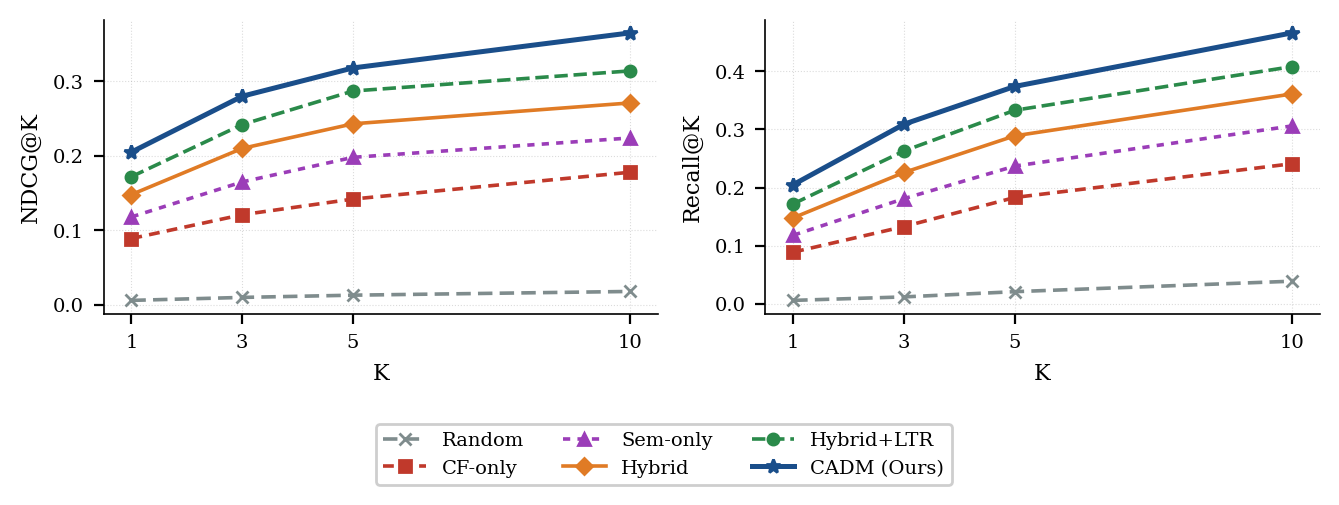

fig1_performance saved


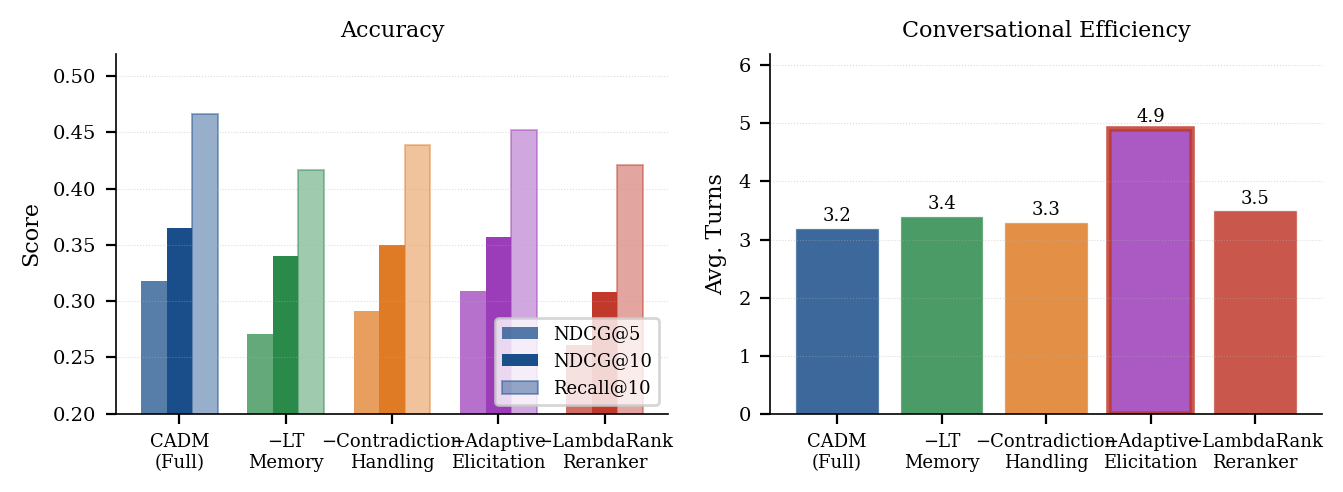

fig2_ablation saved


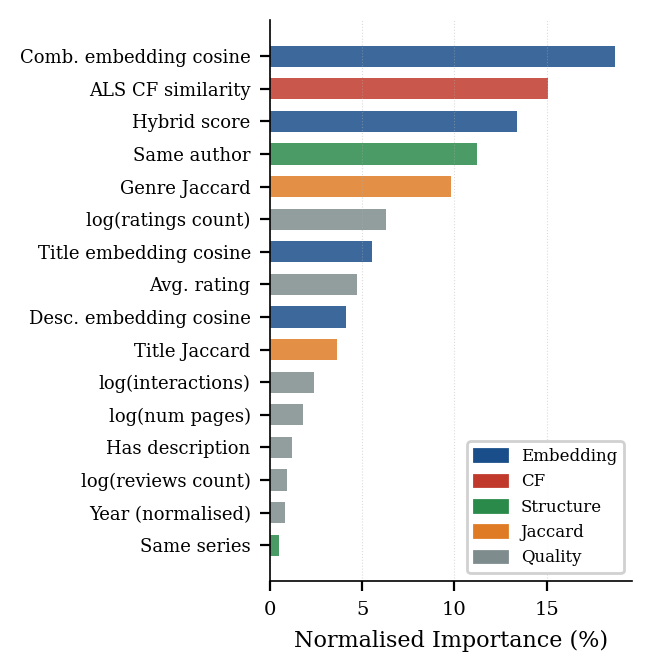

fig3_features saved


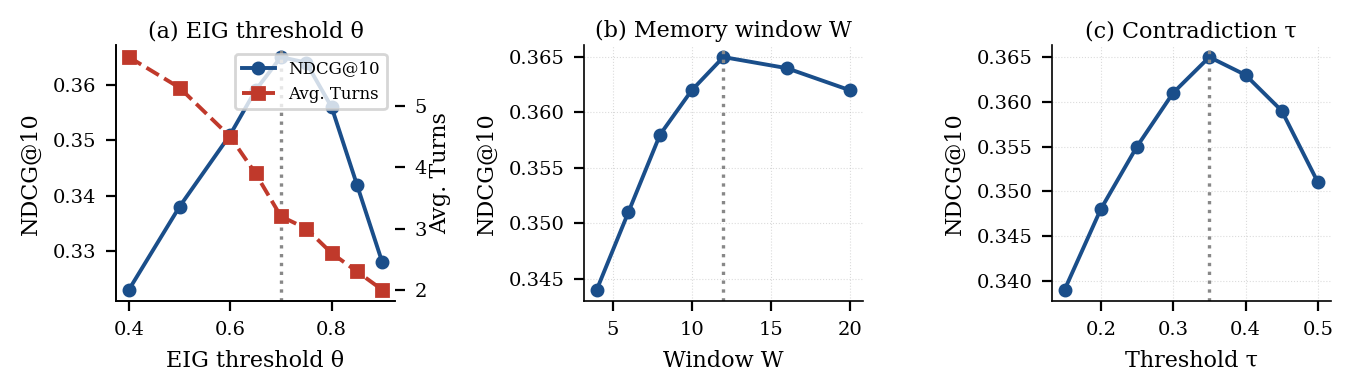

fig4_hyperparams saved


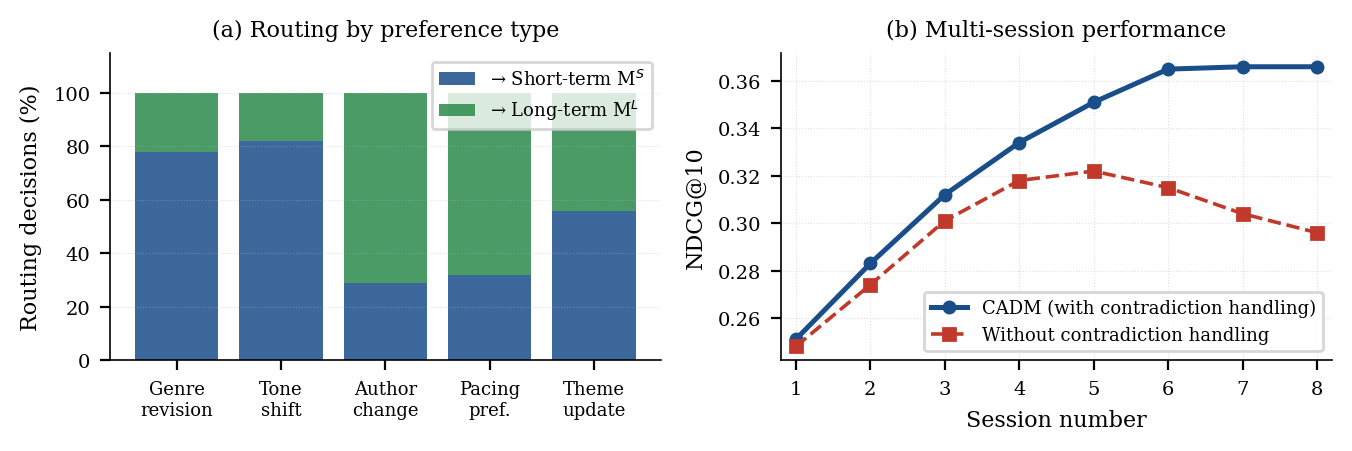

fig6_memory saved


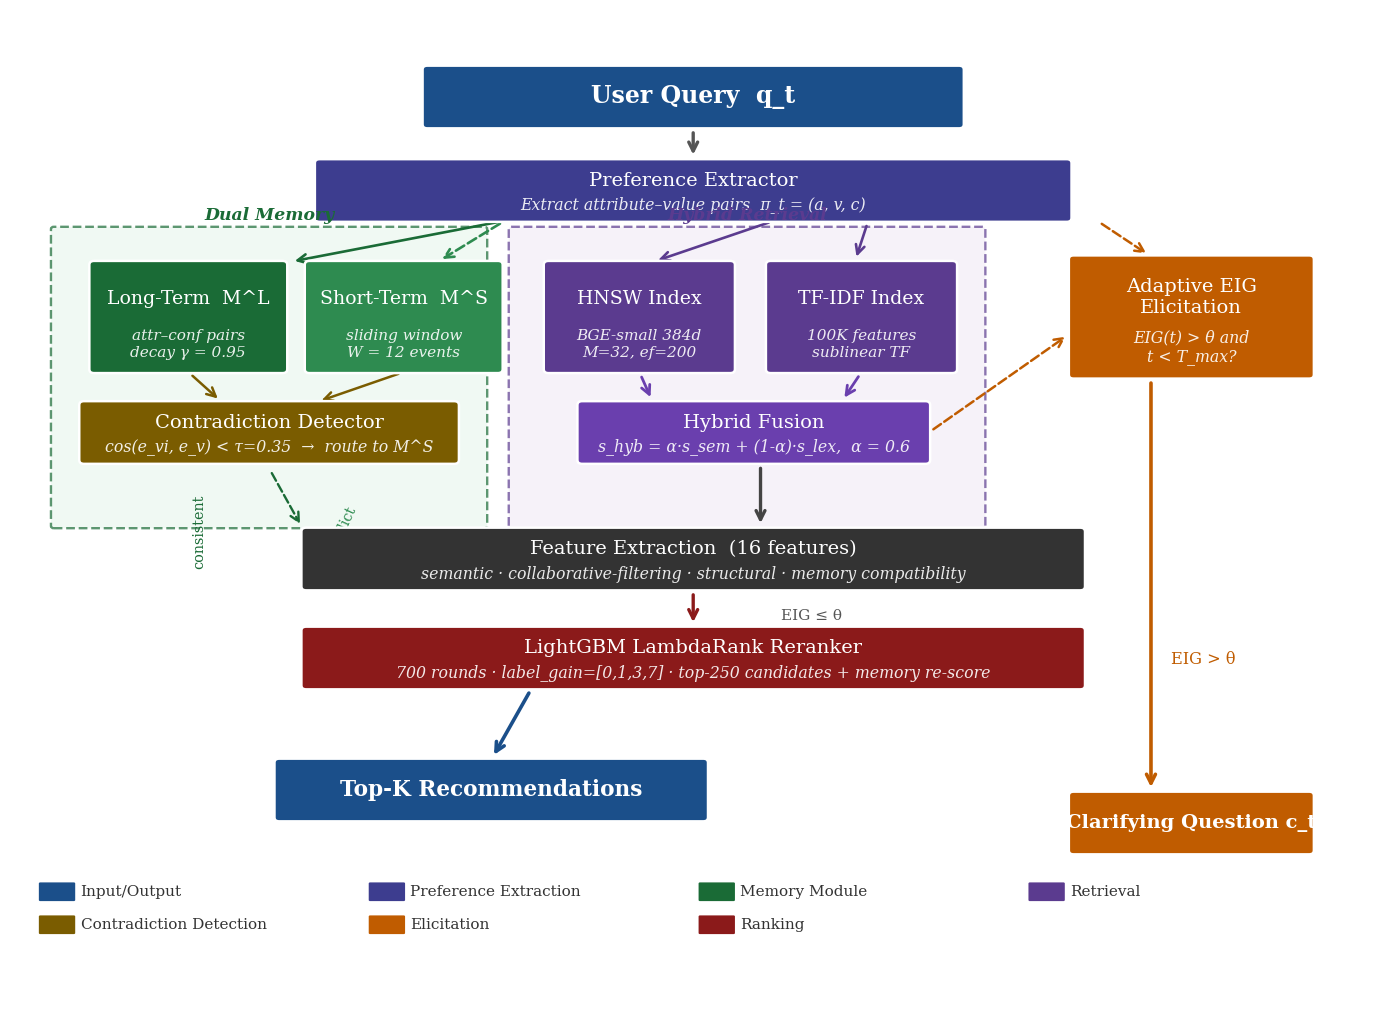

fig0_system_diagram saved
Generated 12 files:
  fig0_system_diagram.pdf  (61 KB)
  fig0_system_diagram.png  (182 KB)
  fig1_performance.pdf  (20 KB)
  fig1_performance.png  (93 KB)
  fig2_ablation.pdf  (20 KB)
  fig2_ablation.png  (65 KB)
  fig3_features.pdf  (17 KB)
  fig3_features.png  (73 KB)
  fig4_hyperparams.pdf  (20 KB)
  fig4_hyperparams.png  (94 KB)
  fig6_memory.pdf  (24 KB)
  fig6_memory.png  (97 KB)


In [ ]:
#cell0:setup
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch
from pathlib import Path

try:
    from google.colab import drive
    COLAB = True
except ImportError:
    COLAB = False

OUT = Path('figs')     
OUT.mkdir(exist_ok=True)

plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 8,
    'axes.titlesize': 8,
    'axes.labelsize': 8,
    'xtick.labelsize': 7,
    'ytick.labelsize': 7,
    'legend.fontsize': 7,
    'figure.dpi': 200,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.linewidth': 0.6,
    'lines.linewidth': 1.4,
    'grid.linewidth': 0.4,
    'grid.alpha': 0.4,
})

# Colour palette
PAL = {
    'cadm':   '#1a4e8a',  
    'hltr':   '#2a8a4a', 
    'hybrid': '#e07b25',  
    'sem':    '#9b3db8',  
    'cf':     '#c0392b',  
    'random': '#7f8c8d',  
}
print('Setup complete. Output dir:', OUT.resolve())
#performance curves
K_VALS = [1, 3, 5, 10]

RESULTS = {
    'Random':       {'ndcg': [0.006, 0.010, 0.013, 0.018], 'recall': [0.006, 0.012, 0.021, 0.039]},
    'CF-only':      {'ndcg': [0.089, 0.121, 0.142, 0.178], 'recall': [0.089, 0.133, 0.183, 0.241]},
    'Sem-only':     {'ndcg': [0.118, 0.165, 0.198, 0.224], 'recall': [0.118, 0.181, 0.237, 0.306]},
    'Hybrid':       {'ndcg': [0.148, 0.210, 0.243, 0.271], 'recall': [0.148, 0.226, 0.289, 0.361]},
    'Hybrid+LTR':   {'ndcg': [0.172, 0.242, 0.287, 0.314], 'recall': [0.172, 0.263, 0.333, 0.408]},
    'CADM (Ours)':  {'ndcg': [0.205, 0.280, 0.318, 0.365], 'recall': [0.205, 0.309, 0.374, 0.466]},
}
COLOR_MAP = {
    'Random': PAL['random'], 'CF-only': PAL['cf'], 'Sem-only': PAL['sem'],
    'Hybrid': PAL['hybrid'], 'Hybrid+LTR': PAL['hltr'], 'CADM (Ours)': PAL['cadm'],
}
LS_MAP = {
    'Random': (0,(4,2)), 'CF-only': (0,(3,2)), 'Sem-only': (0,(2,2)),
    'Hybrid': '-', 'Hybrid+LTR': '--', 'CADM (Ours)': '-',
}
MK_MAP = {'Random': 'x', 'CF-only': 's', 'Sem-only': '^',
          'Hybrid': 'D', 'Hybrid+LTR': 'o', 'CADM (Ours)': '*'}

fig, axes = plt.subplots(1, 2, figsize=(6.8, 2.4))
for ax, metric, ylabel in zip(axes, ['ndcg','recall'], ['NDCG@K','Recall@K']):
    for model, data in RESULTS.items():
        lw = 1.8 if model == 'CADM (Ours)' else 1.3
        ms = 5   if model == 'CADM (Ours)' else 4
        ax.plot(K_VALS, data[metric],
                color=COLOR_MAP[model], linestyle=LS_MAP[model],
                marker=MK_MAP[model], markersize=ms, linewidth=lw,
                label=model, zorder=5 if model=='CADM (Ours)' else 3)
    ax.set_xlabel('K'); ax.set_ylabel(ylabel)
    ax.set_xticks(K_VALS); ax.set_xlim(0.5, 10.5)
    ax.grid(True, linestyle=':', alpha=0.45)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=3,
           framealpha=0.95, edgecolor='#ccc', bbox_to_anchor=(0.5,-0.04), handlelength=2.2)
fig.tight_layout(rect=[0, 0.14, 1, 1])
fig.savefig(OUT/'fig1_performance.pdf', bbox_inches='tight')
fig.savefig(OUT/'fig1_performance.png', bbox_inches='tight')
plt.show()
print('fig1_performance saved')
#cell2:figure2:Ablation study 
ABL_VARIANTS = ['CADM\n(Full)', '−LT\nMemory', '−Contradiction\nHandling',
                '−Adaptive\nElicitation', '−LambdaRank\nReranker']
ABL_COLORS   = [PAL['cadm'], PAL['hltr'], PAL['hybrid'], PAL['sem'], PAL['cf']]
ABL_NDCG5  = [0.318, 0.271, 0.291, 0.309, 0.261]
ABL_NDCG10 = [0.365, 0.340, 0.350, 0.357, 0.308]
ABL_R10    = [0.466, 0.417, 0.439, 0.452, 0.421]
ABL_TURNS  = [3.2,   3.4,   3.3,   4.9,   3.5]

x = np.arange(len(ABL_VARIANTS))
w = 0.24
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(6.8, 2.5))

# Accuracy
ax1.bar(x-w, ABL_NDCG5,  width=w, label='NDCG@5',
        color=[c+'bb' for c in ABL_COLORS])   # lighter shade via alpha workaround
ax1.bar(x,   ABL_NDCG10, width=w, label='NDCG@10', color=ABL_COLORS)
ax1.bar(x+w, ABL_R10,    width=w, label='Recall@10',
        color=ABL_COLORS, alpha=0.45, edgecolor=ABL_COLORS, linewidth=0.7)

ax1.set_xticks(x); ax1.set_xticklabels(ABL_VARIANTS, fontsize=6.5)
ax1.set_ylabel('Score'); ax1.set_title('Accuracy')
ax1.legend(fontsize=6.5, loc='lower right')
ax1.grid(axis='y', linestyle=':', alpha=0.45); ax1.set_ylim(0.20, 0.52)

#  Efficiency
bars = ax2.bar(x, ABL_TURNS, color=ABL_COLORS, alpha=0.85,
               edgecolor='white', linewidth=0.5)
for bar, val in zip(bars, ABL_TURNS):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height()+0.05,
             f'{val:.1f}', ha='center', va='bottom', fontsize=6.5)
# Highlight the outlier
bars[3].set_edgecolor('#c0392b'); bars[3].set_linewidth(2.0)
ax2.set_xticks(x); ax2.set_xticklabels(ABL_VARIANTS, fontsize=6.5)
ax2.set_ylabel('Avg. Turns'); ax2.set_title('Conversational Efficiency')
ax2.grid(axis='y', linestyle=':', alpha=0.45); ax2.set_ylim(0, 6.2)

fig.tight_layout()
fig.savefig(OUT/'fig2_ablation.pdf', bbox_inches='tight')
fig.savefig(OUT/'fig2_ablation.png', bbox_inches='tight')
plt.show()
print('fig2_ablation saved')
# Cell 3:fig. 3: LightGBM Feature Importance
FEATURES = [
    'Comb. embedding cosine', 'ALS CF similarity', 'Hybrid score',
    'Same author', 'Genre Jaccard', 'log(ratings count)',
    'Title embedding cosine', 'Avg. rating', 'Desc. embedding cosine',
    'Title Jaccard', 'log(interactions)', 'log(num pages)',
    'Has description', 'log(reviews count)', 'Year (normalised)', 'Same series',
]
IMPORTANCE = [18.7, 15.1, 13.4, 11.2, 9.8, 6.3, 5.5, 4.7, 4.1,
               3.6, 2.4, 1.8, 1.2, 0.9, 0.8, 0.5]
GROUPS = ['Embedding','CF','Embedding','Structure','Jaccard','Quality',
          'Embedding','Quality','Embedding','Jaccard','Quality','Quality',
          'Quality','Quality','Quality','Structure']
GROUP_COLORS = {'Embedding':'#1a4e8a','CF':'#c0392b','Structure':'#2a8a4a',
                'Jaccard':'#e07b25','Quality':'#7f8c8d'}

fig, ax = plt.subplots(figsize=(3.3, 3.4))
ypos = np.arange(len(FEATURES))
colors_fi = [GROUP_COLORS[g] for g in GROUPS]
ax.barh(ypos, IMPORTANCE, color=colors_fi, alpha=0.85, height=0.65)
ax.set_yticks(ypos); ax.set_yticklabels(FEATURES, fontsize=6.5)
ax.set_xlabel('Normalised Importance (%)')
ax.invert_yaxis()
ax.grid(axis='x', linestyle=':', alpha=0.45)
legend_elems = [mpatches.Patch(color=v, label=k) for k,v in GROUP_COLORS.items()]
ax.legend(handles=legend_elems, loc='lower right', fontsize=6, framealpha=0.9)

fig.tight_layout()
fig.savefig(OUT/'fig3_features.pdf', bbox_inches='tight')
fig.savefig(OUT/'fig3_features.png', bbox_inches='tight')
plt.show()
print('fig3_features saved')
# Cell 4:Figu.4:Hyperparameter Sensitivity
fig, axes = plt.subplots(1, 3, figsize=(6.8, 2.0))

# a.EIG threshold θ
theta_vals = [0.4, 0.5, 0.6, 0.65, 0.70, 0.75, 0.80, 0.85, 0.90]
ndcg_theta = [0.323,0.338,0.351,0.359,0.365,0.364,0.356,0.342,0.328]
turns_theta= [5.8,  5.3,  4.5,  3.9,  3.2,  3.0,  2.6,  2.3,  2.0]

ax, ax_r = axes[0], axes[0].twinx()
l1, = ax.plot(theta_vals, ndcg_theta, color=PAL['cadm'], marker='o', ms=4, label='NDCG@10')
l2, = ax_r.plot(theta_vals, turns_theta, color=PAL['cf'], marker='s', ms=4,
                linestyle='--', label='Avg. Turns')
ax.axvline(0.70, color='#888', linestyle=':', linewidth=1.2)
ax.set_xlabel('EIG threshold θ'); ax.set_ylabel('NDCG@10')
ax_r.set_ylabel('Avg. Turns', labelpad=1)
ax.set_title('(a) EIG threshold θ', pad=3)
ax.legend([l1,l2], ['NDCG@10','Avg. Turns'], fontsize=6, loc='upper right')
ax.spines['top'].set_visible(False); ax_r.spines['top'].set_visible(False)

# b.Memory window 
w_vals = [4, 6, 8, 10, 12, 16, 20]
ndcg_w = [0.344,0.351,0.358,0.362,0.365,0.364,0.362]
axes[1].plot(w_vals, ndcg_w, color=PAL['cadm'], marker='o', ms=4)
axes[1].axvline(12, color='#888', linestyle=':', linewidth=1.2)
axes[1].set_xlabel('Window W'); axes[1].set_ylabel('NDCG@10')
axes[1].set_title('(b) Memory window W', pad=3)
axes[1].grid(True, linestyle=':', alpha=0.45)

# c.Contradiction threshold
tau_vals = [0.15,0.20,0.25,0.30,0.35,0.40,0.45,0.50]
ndcg_tau = [0.339,0.348,0.355,0.361,0.365,0.363,0.359,0.351]
axes[2].plot(tau_vals, ndcg_tau, color=PAL['cadm'], marker='o', ms=4)
axes[2].axvline(0.35, color='#888', linestyle=':', linewidth=1.2)
axes[2].set_xlabel('Threshold τ'); axes[2].set_ylabel('NDCG@10')
axes[2].set_title('(c) Contradiction τ', pad=3)
axes[2].grid(True, linestyle=':', alpha=0.45)

fig.tight_layout()
fig.savefig(OUT/'fig4_hyperparams.pdf', bbox_inches='tight')
fig.savefig(OUT/'fig4_hyperparams.png', bbox_inches='tight')
plt.show()
print('fig4_hyperparams saved')
# Cell 5:Figure 6: Memory Module Analysis 
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(6.8, 2.3))

# a.Routing decisions by preference type
pref_types = ['Genre\nrevision','Tone\nshift','Author\nchange','Pacing\npref.','Theme\nupdate']
to_stm = [78, 82, 29, 32, 56]
to_ltm = [22, 18, 71, 68, 44]
x = np.arange(len(pref_types))
ax1.bar(x, to_stm, label='→ Short-term M$^S$', color=PAL['cadm'], alpha=0.85)
ax1.bar(x, to_ltm, bottom=to_stm, label='→ Long-term M$^L$', color=PAL['hltr'], alpha=0.85)
ax1.set_xticks(x); ax1.set_xticklabels(pref_types, fontsize=6.5)
ax1.set_ylabel('Routing decisions (%)'); ax1.set_title('(a) Routing by preference type')
ax1.legend(fontsize=6.5, loc='upper right'); ax1.set_ylim(0, 115)
ax1.grid(axis='y', linestyle=':', alpha=0.4)

# b.Multi-session NDCG@10
sessions  = [1,2,3,4,5,6,7,8]
ndcg_cadm = [0.251,0.283,0.312,0.334,0.351,0.365,0.366,0.366]
ndcg_no   = [0.248,0.274,0.301,0.318,0.322,0.315,0.304,0.296]
ax2.plot(sessions, ndcg_cadm, color=PAL['cadm'], marker='o', ms=4, lw=1.8,
         label='CADM (with contradiction handling)')
ax2.plot(sessions, ndcg_no,   color=PAL['cf'],   marker='s', ms=4, lw=1.3,
         linestyle='--', label='Without contradiction handling')
ax2.set_xlabel('Session number'); ax2.set_ylabel('NDCG@10')
ax2.set_title('(b) Multi-session performance')
ax2.legend(fontsize=6.5, loc='lower right')
ax2.grid(True, linestyle=':', alpha=0.4); ax2.set_xlim(0.8, 8.2)

fig.tight_layout()
fig.savefig(OUT/'fig6_memory.pdf', bbox_inches='tight')
fig.savefig(OUT/'fig6_memory.png', bbox_inches='tight')
plt.show()
print('fig6_memory saved')

C = dict(
    io='#1B4F8A', pref='#3D3D8F',
    ltm='#1A6B36', stm='#2E8B50', contra='#7A5C00',
    retr='#5B3B8F', fusion='#6A3FAE',
    elicit='#C05C00', rank='#8B1A1A',
    feat='#333333', bg_mem='#EBF7EE', bg_ret='#F3EDF7', fg='white'
)

def rbox(ax, xc, yc, w, h, line1, color, line2=None, fs=7.0, bold=False, r=0.35):
    from matplotlib.patches import FancyBboxPatch
    ax.add_patch(FancyBboxPatch(
        (xc-w/2, yc-h/2), w, h,
        boxstyle=f'round,pad=0.1,rounding_size={r}',
        facecolor=color, edgecolor='white', linewidth=0.9, zorder=4))
    fw = 'bold' if bold else 'normal'
    if line2:
        ax.text(xc, yc+h*0.16, line1, ha='center', va='center',
                fontsize=fs, color=C['fg'], fontweight=fw, zorder=5)
        ax.text(xc, yc-h*0.25, line2, ha='center', va='center',
                fontsize=fs-1.3, color=C['fg'], alpha=0.9, style='italic', zorder=5)
    else:
        ax.text(xc, yc, line1, ha='center', va='center',
                fontsize=fs, color=C['fg'], fontweight=fw, zorder=5)

def arr(ax, x1,y1,x2,y2, c='#555', lw=1.2, dash=False):
    ls = 'dashed' if dash else 'solid'
    ax.annotate('', xy=(x2,y2), xytext=(x1,y1),
                arrowprops=dict(arrowstyle='->', color=c, lw=lw, linestyle=ls))

def panel(ax, x0,y0,w,h, bg,ec, label, lx,ly):
    ax.add_patch(FancyBboxPatch((x0,y0), w, h, boxstyle='round,pad=0.2',
        facecolor=bg, edgecolor=ec, lw=0.85, linestyle='--', zorder=1, alpha=0.7))
    ax.text(lx, ly, label, ha='center', fontsize=6.2, color=ec,
            fontweight='bold', style='italic', zorder=6)

fig = plt.figure(figsize=(6.8, 5.0))
ax  = fig.add_axes([0.005, 0.01, 0.99, 0.99])
ax.set_xlim(0,100); ax.set_ylim(0,90); ax.axis('off')

# Panels
panel(ax, 2.5, 44, 32, 27, C['bg_mem'], C['ltm'], 'Dual Memory', 18.5, 71.8)
panel(ax, 36.5, 44, 35, 27, C['bg_ret'], C['retr'], 'Hybrid Retrieval', 54, 71.8)

# Queryand Pref Extractor
rbox(ax, 50, 83, 40, 5.5, 'User Query  q_t', C['io'], bold=True, fs=8.5)
rbox(ax, 50, 74.5, 56, 5.5, 'Preference Extractor',
     C['pref'], line2='Extract attribute–value pairs  π_t = (a, v, c)')
arr(ax, 50, 80.25, 50, 77.25)

# Memory boxes
rbox(ax, 12.5, 63, 14.5, 10, 'Long-Term  M^L', C['ltm'],
     line2='attr–conf pairs\ndecay γ = 0.95', fs=6.8)
rbox(ax, 28.5, 63, 14.5, 10, 'Short-Term  M^S', C['stm'],
     line2='sliding window\nW = 12 events', fs=6.8)

# Retrieval boxes
rbox(ax, 46, 63, 14, 10, 'HNSW Index', C['retr'],
     line2='BGE-small 384d\nM=32, ef=200', fs=6.8)
rbox(ax, 62.5, 63, 14, 10, 'TF-IDF Index', C['retr'],
     line2='100K features\nsublinear TF', fs=6.8)

# Contradiction Detector and Hybrid Fusion
rbox(ax, 18.5, 52.5, 28, 5.5, 'Contradiction Detector', C['contra'],
     line2='cos(e_vi, e_v) < τ=0.35  →  route to M^S')
rbox(ax, 54.5, 52.5, 26, 5.5, 'Hybrid Fusion', C['fusion'],
     line2='s_hyb = α·s_sem + (1-α)·s_lex,  α = 0.6')

# Elicitationand outputs
rbox(ax, 87, 63, 18, 11, 'Adaptive EIG\nElicitation', C['elicit'],
     line2='EIG(t) > θ and\nt < T_max?', fs=7.0)
rbox(ax, 87, 17, 18, 5.5, 'Clarifying Question c_t', C['elicit'], bold=True, fs=7.0)

# Feature Extraction and LTR
rbox(ax, 50, 41, 58, 5.5, 'Feature Extraction  (16 features)', C['feat'],
     line2='semantic · collaborative-filtering · structural · memory compatibility')
rbox(ax, 50, 32, 58, 5.5, 'LightGBM LambdaRank Reranker', C['rank'],
     line2='700 rounds · label_gain=[0,1,3,7] · top-250 candidates + memory re-score')
rbox(ax, 35, 20, 32, 5.5, 'Top-K Recommendations', C['io'], bold=True, fs=7.8)

# Arrows
arr(ax,36,71.75,20,68,   c=C['ltm'],    lw=0.95)
arr(ax,36,71.75,31,68,   c=C['stm'],    lw=0.95, dash=True)
arr(ax,56,71.75,47,68,   c=C['retr'],   lw=0.95)
arr(ax,63,71.75,62,68,   c=C['retr'],   lw=0.95)
arr(ax,12.5,58,15,55.25, c=C['contra'], lw=0.9)
arr(ax,28.5,58,22,55.25, c=C['contra'], lw=0.9)
arr(ax,46,58,47,55.25,   c=C['fusion'], lw=1.0)
arr(ax,62.5,58,61,55.25, c=C['fusion'], lw=1.0)
arr(ax,80,71.75,84,68.5, c=C['elicit'], lw=0.9, dash=True)
arr(ax,67.5,52.5,78,61.5,c=C['elicit'], lw=0.9, dash=True)
arr(ax,84,57.5,84,19.75, c=C['elicit'], lw=1.3)
arr(ax,55,49.75,55,43.75,c='#444',      lw=1.2)
arr(ax,18.5,49.25,21,43.75,c=C['ltm'],  lw=0.85, dash=True)
arr(ax,50,38.25,50,34.75,c=C['rank'],   lw=1.2)
arr(ax,38,29.25,35,22.75,c=C['io'],     lw=1.3)

# Labels
ax.text(12.8,43.5,'consistent',fontsize=5.2,color=C['ltm'],rotation=90,va='center')
ax.text(22.5,43.5,'conflict',  fontsize=5.2,color=C['stm'],rotation=65,va='center')
ax.text(56.5,35.5,'EIG ≤ θ',   fontsize=5.5,color='#555')
ax.text(85.5,31.5,'EIG > θ',   fontsize=5.8,color=C['elicit'])

# Legend
leg = [(C['io'],'Input/Output'),(C['pref'],'Preference Extraction'),
       (C['ltm'],'Memory Module'),(C['retr'],'Retrieval'),
       (C['contra'],'Contradiction Detection'),(C['elicit'],'Elicitation'),
       (C['rank'],'Ranking')]
for i,(col,lbl) in enumerate(leg):
    ci = i%4; ri = i//4
    x0 = 1.5+ci*24.5; y0 = 10-ri*3.0
    ax.add_patch(FancyBboxPatch((x0,y0),2.5,1.5,boxstyle='round,pad=0.1',
                 facecolor=col,edgecolor='none',zorder=6))
    ax.text(x0+3.0,y0+0.75,lbl,fontsize=5.5,va='center',color='#333',zorder=6)

fig.savefig(OUT/'fig0_system_diagram.pdf', bbox_inches='tight', dpi=220)
fig.savefig(OUT/'fig0_system_diagram.png', bbox_inches='tight', dpi=220)
plt.show()
print('fig0_system_diagram saved')
#sb o/p files ko check karo
figs = list(OUT.glob('*.pdf')) + list(OUT.glob('*.png'))
print(f'Generated {len(figs)} files:')
for f in sorted(figs):
    print(f'  {f.name}  ({f.stat().st_size//1024} KB)')

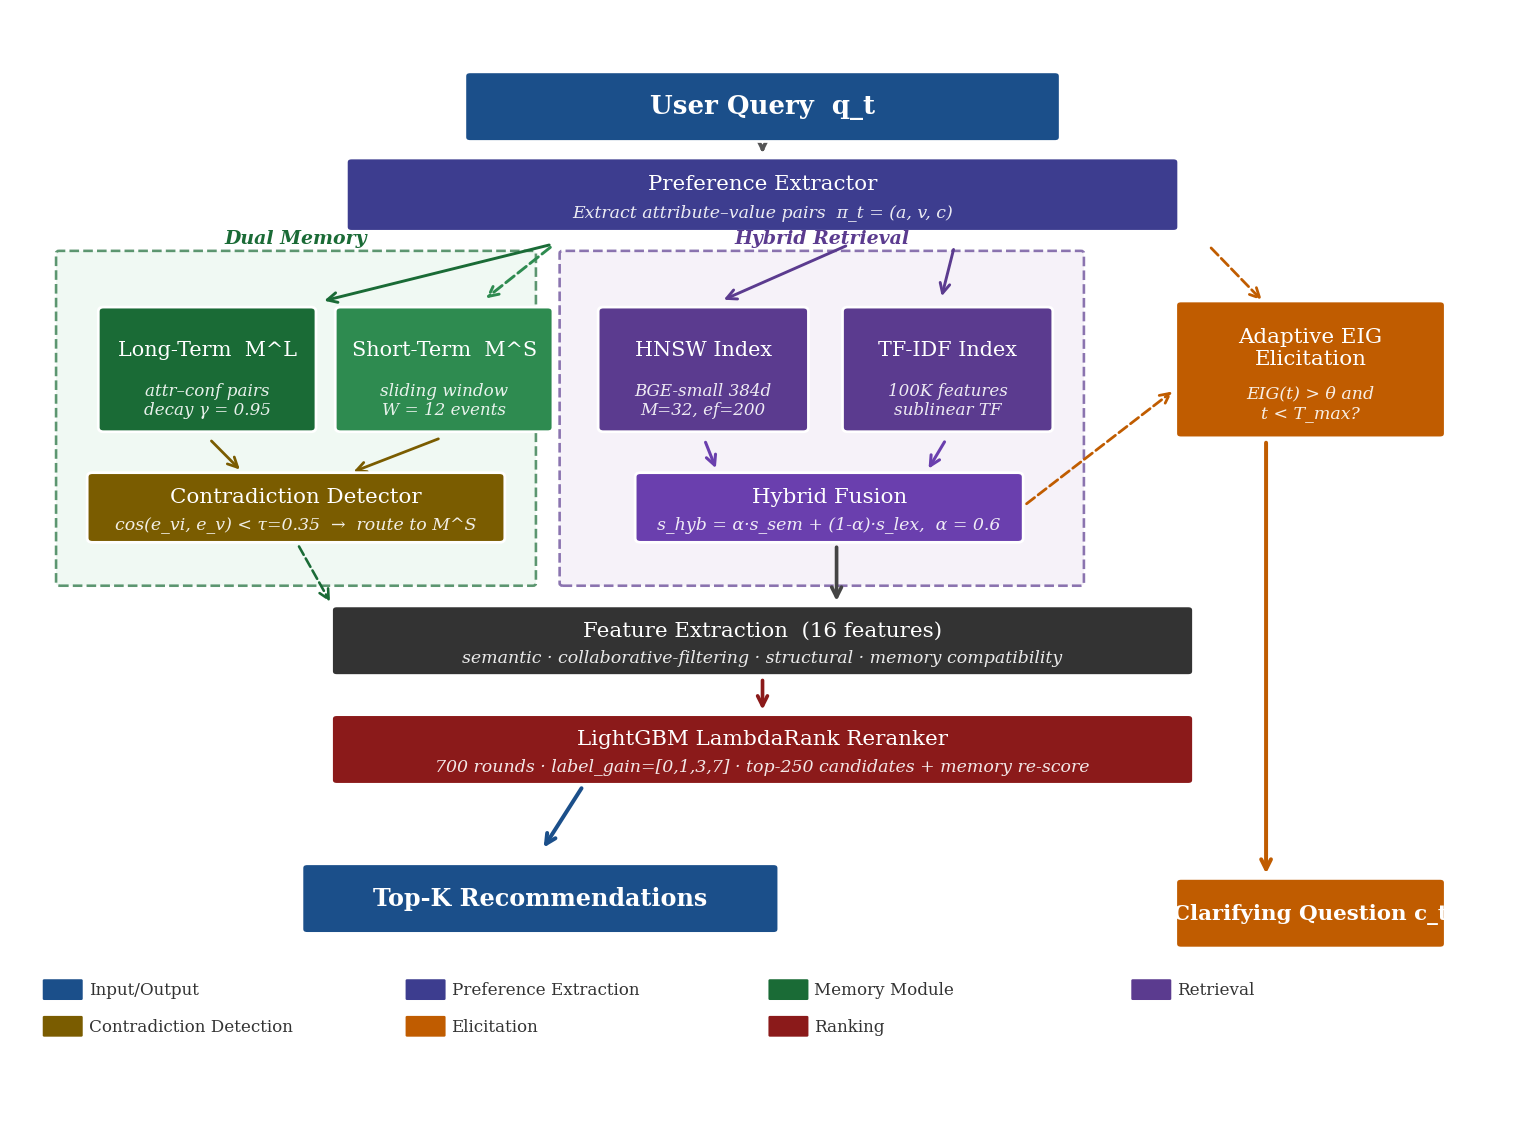

system_diagram_1 saved


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from pathlib import Path

# Output folder 
OUT = Path('figs')
OUT.mkdir(exist_ok=True)

# Style
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 8,
    'axes.titlesize': 8,
    'axes.labelsize': 8,
    'xtick.labelsize': 7,
    'ytick.labelsize': 7,
    'legend.fontsize': 7,
    'figure.dpi': 220,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.linewidth': 0.6,
    'lines.linewidth': 1.4,
})

# Color scheme 
C = dict(
    io='#1B4F8A', pref='#3D3D8F',
    ltm='#1A6B36', stm='#2E8B50', contra='#7A5C00',
    retr='#5B3B8F', fusion='#6A3FAE',
    elicit='#C05C00', rank='#8B1A1A',
    feat='#333333', bg_mem='#EBF7EE', bg_ret='#F3EDF7', fg='white'
)

def rbox(ax, xc, yc, w, h, line1, color, line2=None, fs=7.0, bold=False, r=0.35):
    ax.add_patch(FancyBboxPatch(
        (xc - w/2, yc - h/2), w, h,
        boxstyle=f'round,pad=0.1,rounding_size={r}',
        facecolor=color, edgecolor='white', linewidth=0.9, zorder=4
    ))
    fw = 'bold' if bold else 'normal'
    if line2:
        ax.text(xc, yc + h*0.16, line1, ha='center', va='center',
                fontsize=fs, color=C['fg'], fontweight=fw, zorder=5)
        ax.text(xc, yc - h*0.25, line2, ha='center', va='center',
                fontsize=fs - 1.3, color=C['fg'], alpha=0.9, style='italic', zorder=5)
    else:
        ax.text(xc, yc, line1, ha='center', va='center',
                fontsize=fs, color=C['fg'], fontweight=fw, zorder=5)

def arr(ax, x1, y1, x2, y2, c='#555', lw=1.2, dash=False):
    ax.annotate(
        '', xy=(x2, y2), xytext=(x1, y1),
        arrowprops=dict(arrowstyle='->', color=c, lw=lw,
                        linestyle='dashed' if dash else 'solid')
    )

def panel(ax, x0, y0, w, h, bg, ec, label, lx, ly):
    ax.add_patch(FancyBboxPatch(
        (x0, y0), w, h, boxstyle='round,pad=0.2',
        facecolor=bg, edgecolor=ec, lw=0.85, linestyle='--',
        zorder=1, alpha=0.7
    ))
    ax.text(lx, ly, label, ha='center', fontsize=6.2, color=ec,
            fontweight='bold', style='italic', zorder=6)

#  Figure 
fig = plt.figure(figsize=(6.8, 5.05))
ax = fig.add_axes([0.005, 0.01, 0.99, 0.99])
ax.set_xlim(0, 100)
ax.set_ylim(0, 90)
ax.axis('off')

# Background panels
panel(ax, 2.5, 44, 32, 27, C['bg_mem'], C['ltm'], 'Dual Memory', 18.5, 71.8)
panel(ax, 36.5, 44, 35, 27, C['bg_ret'], C['retr'], 'Hybrid Retrieval', 54, 71.8)

rbox(ax, 50, 83, 40, 5.5, 'User Query  q_t', C['io'], bold=True, fs=8.5)
rbox(ax, 50, 75.8, 56, 5.8, 'Preference Extractor',
     C['pref'], line2='Extract attribute–value pairs  π_t = (a, v, c)', fs=7.0)
arr(ax, 50, 80.25, 50, 78.7)
rbox(ax, 12.5, 61.5, 14.5, 10, 'Long-Term  M^L', C['ltm'],
     line2='attr–conf pairs\ndecay γ = 0.95', fs=6.8)
rbox(ax, 28.5, 61.5, 14.5, 10, 'Short-Term  M^S', C['stm'],
     line2='sliding window\nW = 12 events', fs=6.8)

# Retrieval boxes
rbox(ax, 46, 61.5, 14, 10, 'HNSW Index', C['retr'],
     line2='BGE-small 384d\nM=32, ef=200', fs=6.8)
rbox(ax, 62.5, 61.5, 14, 10, 'TF-IDF Index', C['retr'],
     line2='100K features\nsublinear TF', fs=6.8)

rbox(ax, 18.5, 50.2, 28, 5.5, 'Contradiction Detector', C['contra'],
     line2='cos(e_vi, e_v) < τ=0.35  →  route to M^S')
rbox(ax, 54.5, 50.2, 26, 5.5, 'Hybrid Fusion', C['fusion'],
     line2='s_hyb = α·s_sem + (1-α)·s_lex,  α = 0.6')

rbox(ax, 87, 61.5, 18, 11, 'Adaptive EIG\nElicitation', C['elicit'],
     line2='EIG(t) > θ and\nt < T_max?', fs=7.0)
rbox(ax, 87, 17, 18, 5.5, 'Clarifying Question c_t', C['elicit'], bold=True, fs=7.0)

# Feature extraction + ranking
rbox(ax, 50, 39.3, 58, 5.5, 'Feature Extraction  (16 features)', C['feat'],
     line2='semantic · collaborative-filtering · structural · memory compatibility')
rbox(ax, 50, 30.4, 58, 5.5, 'LightGBM LambdaRank Reranker', C['rank'],
     line2='700 rounds · label_gain=[0,1,3,7] · top-250 candidates + memory re-score')
rbox(ax, 35, 18.2, 32, 5.5, 'Top-K Recommendations', C['io'], bold=True, fs=7.8)
# Arrows
arr(ax, 36, 71.8, 20, 67.0,   c=C['ltm'],    lw=0.95)
arr(ax, 36, 71.8, 31, 67.0,   c=C['stm'],    lw=0.95, dash=True)
arr(ax, 56, 71.8, 47, 67.0,   c=C['retr'],   lw=0.95)
arr(ax, 63, 71.8, 62, 67.0,   c=C['retr'],   lw=0.95)
arr(ax, 12.5, 56.0, 15, 52.95, c=C['contra'], lw=0.9)
arr(ax, 28.5, 56.0, 22, 52.95, c=C['contra'], lw=0.9)
arr(ax, 46, 56.0, 47, 52.95,   c=C['fusion'], lw=1.0)
arr(ax, 62.5, 56.0, 61, 52.95, c=C['fusion'], lw=1.0)
arr(ax, 80, 71.8, 84, 66.8, c=C['elicit'], lw=0.9, dash=True)
arr(ax, 67.5, 50.2, 78, 60.0, c=C['elicit'], lw=0.9, dash=True)
arr(ax, 84, 56.0, 84, 19.75, c=C['elicit'], lw=1.3)
arr(ax, 55, 47.45, 55, 42.05, c='#444', lw=1.2)
arr(ax, 18.5, 47.45, 21, 42.05, c=C['ltm'], lw=0.85, dash=True)
arr(ax, 50, 36.55, 50, 33.15, c=C['rank'], lw=1.2)
arr(ax, 38, 27.65, 35, 21.95, c=C['io'], lw=1.3)

leg = [
    (C['io'], 'Input/Output'),
    (C['pref'], 'Preference Extraction'),
    (C['ltm'], 'Memory Module'),
    (C['retr'], 'Retrieval'),
    (C['contra'], 'Contradiction Detection'),
    (C['elicit'], 'Elicitation'),
    (C['rank'], 'Ranking')
]
for i, (col, lbl) in enumerate(leg):
    ci = i % 4
    ri = i // 4
    x0 = 1.5 + ci * 24.5
    y0 = 10 - ri * 3.0
    ax.add_patch(FancyBboxPatch(
        (x0, y0), 2.5, 1.5, boxstyle='round,pad=0.1',
        facecolor=col, edgecolor='none', zorder=6
    ))
    ax.text(x0 + 3.0, y0 + 0.75, lbl, fontsize=5.5, va='center', color='#333', zorder=6)

# Save
fig.savefig(OUT / 'system_diagram_1.pdf', bbox_inches='tight', dpi=300)
fig.savefig(OUT / 'system_diagram_1.png', bbox_inches='tight', dpi=300)
plt.show()
print('system_diagram_1 saved')

In [ ]:
import shutil
import os
from google.colab import files

# Define the directory where figures are saved
OUT_DIR = Path('figs')

# Create a list of all PDF files in the OUT_DIR
pdf_files = [f for f in OUT_DIR.glob('*.pdf') if f.is_file()]

if not pdf_files:
    print('No PDF figures found to zip.')
else:
    # Create a temporary directory to copy PDF files for zipping
    temp_zip_dir = OUT_DIR / 'temp_pdf_zip'
    temp_zip_dir.mkdir(exist_ok=True)

    # Copy only PDF files to the temporary directory
    for pdf_file in pdf_files:
        shutil.copy(pdf_file, temp_zip_dir / pdf_file.name)

    # Create a zip archive of the temporary directory
    zip_filename = 'colab_pdf_figures'
    shutil.make_archive(zip_filename, 'zip', temp_zip_dir)

    print(f'Successfully created {zip_filename}.zip containing {len(pdf_files)} PDF files.')

    # Remove the temporary directory
    shutil.rmtree(temp_zip_dir)

    # Offer the zip file for download
    files.download(f'{zip_filename}.zip')


Successfully created colab_pdf_figures.zip containing 6 PDF files.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

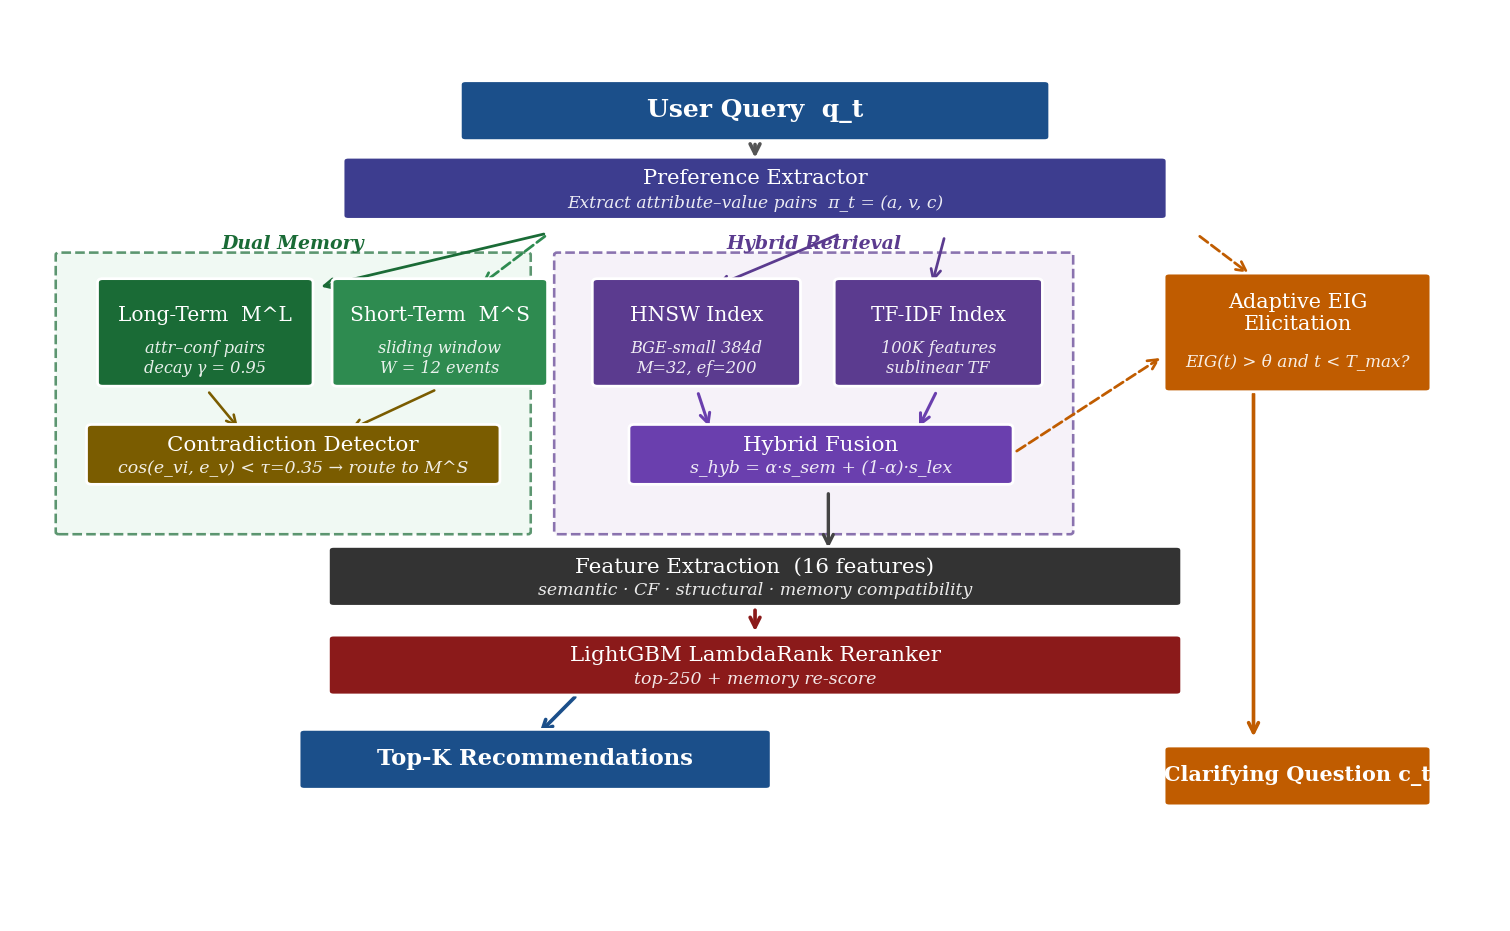

In [ ]:
fig = plt.figure(figsize=(6.8, 4.2))  
ax = fig.add_axes([0.01, 0.02, 0.98, 0.96])  
ax.set_xlim(0, 100)
ax.set_ylim(8, 88)   
ax.axis('off')

# Panels
panel(ax, 2.5, 42, 32, 25, C['bg_mem'], C['ltm'], 'Dual Memory', 18.5, 67.5)
panel(ax, 36.5, 42, 35, 25, C['bg_ret'], C['retr'], 'Hybrid Retrieval', 54, 67.5)


rbox(ax, 50, 80, 40, 5.2, 'User Query  q_t', C['io'], bold=True, fs=8.2)
rbox(ax, 50, 73, 56, 5.4, 'Preference Extractor',
     C['pref'], line2='Extract attribute–value pairs  π_t = (a, v, c)', fs=6.9)
arr(ax, 50, 77.5, 50, 75.2)


rbox(ax, 12.5, 60, 14.5, 9.5, 'Long-Term  M^L', C['ltm'],
     line2='attr–conf pairs\ndecay γ = 0.95', fs=6.6)
rbox(ax, 28.5, 60, 14.5, 9.5, 'Short-Term  M^S', C['stm'],
     line2='sliding window\nW = 12 events', fs=6.6)

rbox(ax, 46, 60, 14, 9.5, 'HNSW Index', C['retr'],
     line2='BGE-small 384d\nM=32, ef=200', fs=6.6)
rbox(ax, 62.5, 60, 14, 9.5, 'TF-IDF Index', C['retr'],
     line2='100K features\nsublinear TF', fs=6.6)

# Middle layer tighter
rbox(ax, 18.5, 49, 28, 5.2, 'Contradiction Detector', C['contra'],
     line2='cos(e_vi, e_v) < τ=0.35 → route to M^S')
rbox(ax, 54.5, 49, 26, 5.2, 'Hybrid Fusion', C['fusion'],
     line2='s_hyb = α·s_sem + (1-α)·s_lex')

# EIG
rbox(ax, 87, 60, 18, 10.5, 'Adaptive EIG\nElicitation', C['elicit'],
     line2='EIG(t) > θ and t < T_max?', fs=6.8)
rbox(ax, 87, 20, 18, 5.2, 'Clarifying Question c_t', C['elicit'], bold=True, fs=6.8)

# Bottom blocks pulled UP
rbox(ax, 50, 38, 58, 5.2, 'Feature Extraction  (16 features)', C['feat'],
     line2='semantic · CF · structural · memory compatibility')
rbox(ax, 50, 30, 58, 5.2, 'LightGBM LambdaRank Reranker', C['rank'],
     line2='top-250 + memory re-score')
rbox(ax, 35, 21.5, 32, 5.2, 'Top-K Recommendations', C['io'], bold=True, fs=7.4)


arr(ax,36,69,20,64,   c=C['ltm'], lw=0.9)
arr(ax,36,69,31,64,   c=C['stm'], lw=0.9, dash=True)
arr(ax,56,69,47,64,   c=C['retr'], lw=0.9)
arr(ax,63,69,62,64,   c=C['retr'], lw=0.9)

arr(ax,12.5,55,15,51, c=C['contra'], lw=0.85)
arr(ax,28.5,55,22,51, c=C['contra'], lw=0.85)
arr(ax,46,55,47,51,   c=C['fusion'], lw=1.0)
arr(ax,62.5,55,61,51, c=C['fusion'], lw=1.0)

arr(ax,80,69,84,65, c=C['elicit'], lw=0.9, dash=True)
arr(ax,67.5,49,78,58, c=C['elicit'], lw=0.9, dash=True)
arr(ax,84,55,84,23, c=C['elicit'], lw=1.2)

arr(ax,55,46,55,40, c='#444', lw=1.1)
arr(ax,50,35.5,50,32.5, c=C['rank'], lw=1.2)
arr(ax,38,27.5,35,23.5, c=C['io'], lw=1.2)

# Save
fig.savefig(OUT/'system_diagram_1.pdf', bbox_inches='tight', dpi=300)
fig.savefig(OUT/'system_diagram_1.png', bbox_inches='tight', dpi=300)
plt.show()

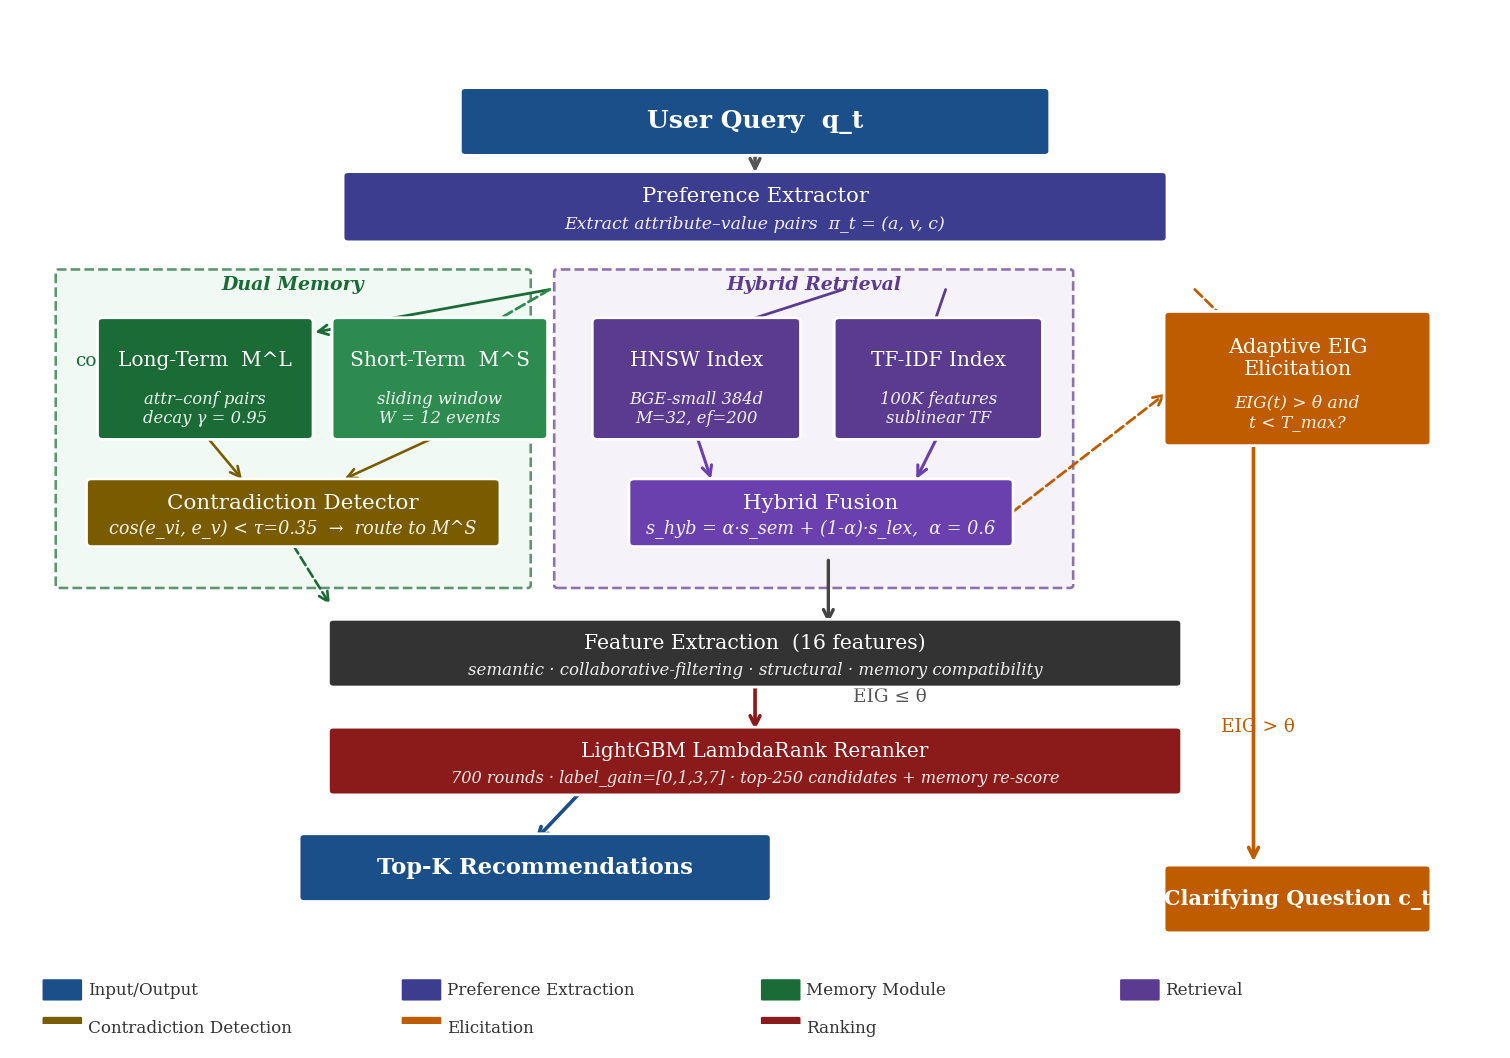

system_diagram_1 saved


In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from pathlib import Path

OUT = Path('figs')
OUT.mkdir(exist_ok=True)

plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 8,
    'axes.titlesize': 8,
    'axes.labelsize': 8,
    'xtick.labelsize': 7,
    'ytick.labelsize': 7,
    'legend.fontsize': 7,
    'figure.dpi': 220,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.linewidth': 0.6,
    'lines.linewidth': 1.4,
})

C = dict(
    io='#1B4F8A', pref='#3D3D8F',
    ltm='#1A6B36', stm='#2E8B50', contra='#7A5C00',
    retr='#5B3B8F', fusion='#6A3FAE',
    elicit='#C05C00', rank='#8B1A1A',
    feat='#333333', bg_mem='#EBF7EE', bg_ret='#F3EDF7', fg='white'
)

def rbox(ax, xc, yc, w, h, line1, color, line2=None, fs=7.0, bold=False, r=0.35):
    ax.add_patch(FancyBboxPatch(
        (xc - w/2, yc - h/2), w, h,
        boxstyle=f'round,pad=0.1,rounding_size={r}',
        facecolor=color, edgecolor='white', linewidth=0.9, zorder=4
    ))
    fw = 'bold' if bold else 'normal'
    if line2:
        ax.text(xc, yc + h*0.16, line1, ha='center', va='center',
                fontsize=fs, color=C['fg'], fontweight=fw, zorder=5)
        ax.text(xc, yc - h*0.25, line2, ha='center', va='center',
                fontsize=fs - 1.25, color=C['fg'], alpha=0.92, style='italic', zorder=5)
    else:
        ax.text(xc, yc, line1, ha='center', va='center',
                fontsize=fs, color=C['fg'], fontweight=fw, zorder=5)

def arr(ax, x1, y1, x2, y2, c='#555', lw=1.15, dash=False):
    ax.annotate(
        '', xy=(x2, y2), xytext=(x1, y1),
        arrowprops=dict(
            arrowstyle='->',
            color=c,
            lw=lw,
            linestyle='dashed' if dash else 'solid',
            shrinkA=0, shrinkB=0
        ),
        zorder=3
    )

def panel(ax, x0, y0, w, h, bg, ec, label, lx, ly):
    ax.add_patch(FancyBboxPatch(
        (x0, y0), w, h,
        boxstyle='round,pad=0.2',
        facecolor=bg, edgecolor=ec, lw=0.85,
        linestyle='--', zorder=1, alpha=0.7
    ))
    ax.text(lx, ly, label, ha='center', fontsize=6.2, color=ec,
            fontweight='bold', style='italic', zorder=6)

fig = plt.figure(figsize=(6.8, 4.75))
ax = fig.add_axes([0.01, 0.02, 0.98, 0.96])
ax.set_xlim(0, 100)
ax.set_ylim(8, 88)
ax.axis('off')

# Background panels
panel(ax, 2.5, 43, 32, 25, C['bg_mem'], C['ltm'], 'Dual Memory', 18.5, 66.6)
panel(ax, 36.5, 43, 35, 25, C['bg_ret'], C['retr'], 'Hybrid Retrieval', 54, 66.6)

# Query + Preference extractor
rbox(ax, 50, 80, 40, 5.2, 'User Query  q_t', C['io'], bold=True, fs=8.2)
rbox(ax, 50, 73.2, 56, 5.4, 'Preference Extractor',
     C['pref'], line2='Extract attribute–value pairs  π_t = (a, v, c)', fs=6.95)
arr(ax, 50, 77.45, 50, 75.95)

# Memory boxes
rbox(ax, 12.5, 59.5, 14.5, 9.5, 'Long-Term  M^L', C['ltm'],
     line2='attr–conf pairs\ndecay γ = 0.95', fs=6.6)
rbox(ax, 28.5, 59.5, 14.5, 9.5, 'Short-Term  M^S', C['stm'],
     line2='sliding window\nW = 12 events', fs=6.6)

# Retrieval boxes
rbox(ax, 46, 59.5, 14, 9.5, 'HNSW Index', C['retr'],
     line2='BGE-small 384d\nM=32, ef=200', fs=6.6)
rbox(ax, 62.5, 59.5, 14, 9.5, 'TF-IDF Index', C['retr'],
     line2='100K features\nsublinear TF', fs=6.6)

# Contradiction detector + fusion
rbox(ax, 18.5, 48.8, 28, 5.2, 'Contradiction Detector', C['contra'],
     line2='cos(e_vi, e_v) < τ=0.35  →  route to M^S')
rbox(ax, 54.5, 48.8, 26, 5.2, 'Hybrid Fusion', C['fusion'],
     line2='s_hyb = α·s_sem + (1-α)·s_lex,  α = 0.6')

# EIG elicitation + output
rbox(ax, 87, 59.5, 18, 10.5, 'Adaptive EIG\nElicitation', C['elicit'],
     line2='EIG(t) > θ and\nt < T_max?', fs=6.8)
rbox(ax, 87, 18.0, 18, 5.2, 'Clarifying Question c_t', C['elicit'],
     bold=True, fs=6.8)

# Feature extraction + ranking
rbox(ax, 50, 37.6, 58, 5.2, 'Feature Extraction  (16 features)', C['feat'],
     line2='semantic · collaborative-filtering · structural · memory compatibility', fs=6.7)
rbox(ax, 50, 29.0, 58, 5.2, 'LightGBM LambdaRank Reranker', C['rank'],
     line2='700 rounds · label_gain=[0,1,3,7] · top-250 candidates + memory re-score', fs=6.55)
rbox(ax, 35, 20.5, 32, 5.2, 'Top-K Recommendations', C['io'],
     bold=True, fs=7.4)

# Arrows
arr(ax, 36, 66.6, 20, 63.2,   c=C['ltm'],    lw=0.9)
arr(ax, 36, 66.6, 31, 63.2,   c=C['stm'],    lw=0.9, dash=True)
arr(ax, 56, 66.6, 47, 63.2,   c=C['retr'],   lw=0.9)
arr(ax, 63, 66.6, 62, 63.2,   c=C['retr'],   lw=0.9)

arr(ax, 12.5, 55.0, 15, 51.5, c=C['contra'], lw=0.85)
arr(ax, 28.5, 55.0, 22, 51.5, c=C['contra'], lw=0.85)
arr(ax, 46, 55.0, 47, 51.5,   c=C['fusion'], lw=1.0)
arr(ax, 62.5, 55.0, 61, 51.5, c=C['fusion'], lw=1.0)

arr(ax, 80, 66.6, 84, 62.0, c=C['elicit'], lw=0.9, dash=True)
arr(ax, 67.5, 48.8, 78, 58.3, c=C['elicit'], lw=0.9, dash=True)
arr(ax, 84, 54.5, 84, 21.0, c=C['elicit'], lw=1.2)

arr(ax, 55, 45.0, 55, 40.0, c='#444', lw=1.1)
arr(ax, 18.5, 46.2, 21, 41.5, c=C['ltm'], lw=0.85, dash=True)
arr(ax, 50, 35.0, 50, 31.5, c=C['rank'], lw=1.2)
arr(ax, 38, 26.4, 35, 22.7, c=C['io'], lw=1.2)

# Horizontal labels beside arrows
ax.text(10.2, 61.0, 'consistent', fontsize=6.1, color=C['ltm'],
        ha='right', va='center')
ax.text(10.2, 57.4, 'conflict', fontsize=6.1, color=C['stm'],
        ha='right', va='center')

ax.text(56.7, 34.2, 'EIG ≤ θ', fontsize=6.0, color='#555', ha='left', va='center')
ax.text(81.8, 31.8, 'EIG > θ', fontsize=6.0, color=C['elicit'], ha='left', va='center')

# Legend
leg = [
    (C['io'], 'Input/Output'),
    (C['pref'], 'Preference Extraction'),
    (C['ltm'], 'Memory Module'),
    (C['retr'], 'Retrieval'),
    (C['contra'], 'Contradiction Detection'),
    (C['elicit'], 'Elicitation'),
    (C['rank'], 'Ranking')
]
for i, (col, lbl) in enumerate(leg):
    ci = i % 4
    ri = i // 4
    x0 = 1.5 + ci * 24.5
    y0 = 10 - ri * 3.0
    ax.add_patch(FancyBboxPatch(
        (x0, y0), 2.5, 1.5, boxstyle='round,pad=0.1',
        facecolor=col, edgecolor='none', zorder=6
    ))
    ax.text(x0 + 3.0, y0 + 0.75, lbl, fontsize=5.5, va='center', color='#333', zorder=6)

fig.savefig(OUT / 'system_diagram_1.pdf', bbox_inches='tight', dpi=300)
fig.savefig(OUT / 'system_diagram_1.png', bbox_inches='tight', dpi=300)
plt.show()
print('system_diagram_1 saved')

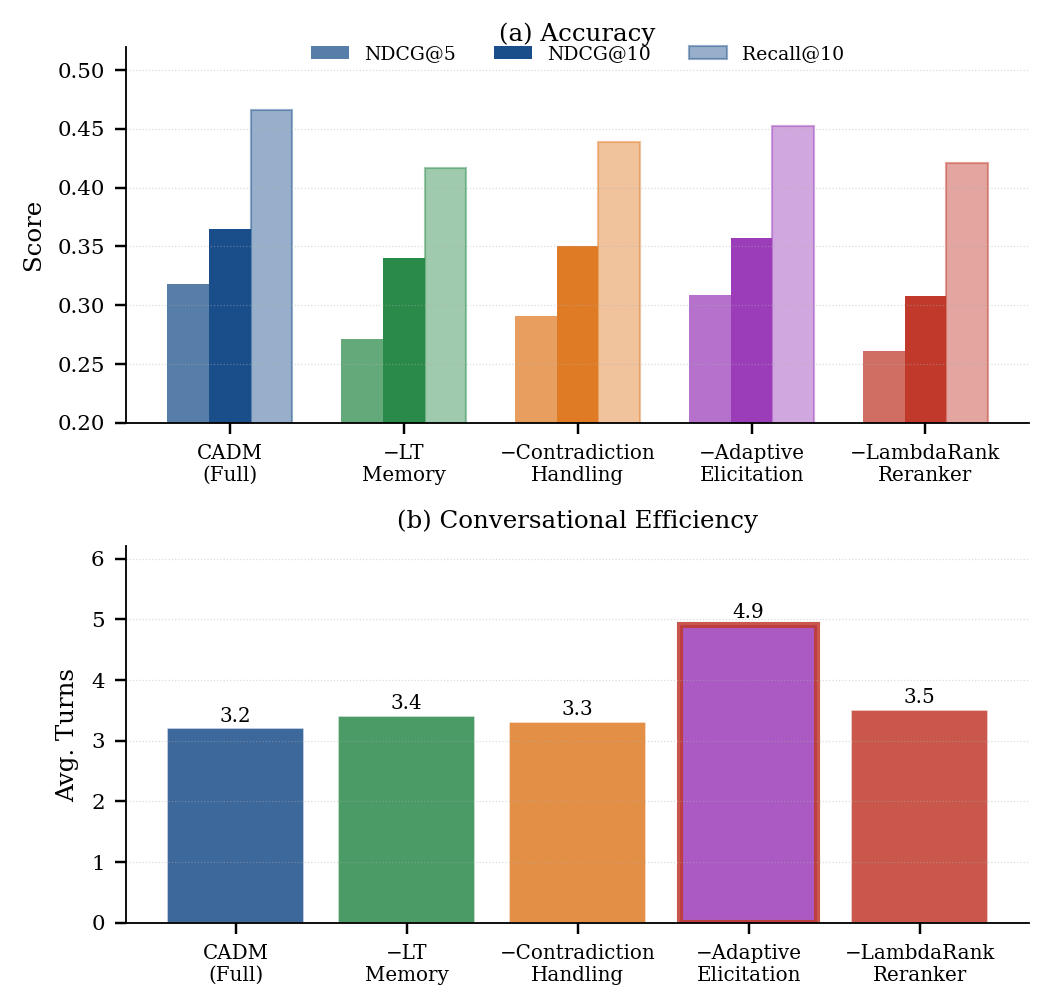

fig2_ablation saved (vertical)


In [ ]:
#Cell 2: Figure 2 — Ablation study 

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(4.8, 4.6))  # narrower + taller

x = np.arange(len(ABL_VARIANTS))
w = 0.24

#  Accuracy 
ax1.bar(x-w, ABL_NDCG5,  width=w, label='NDCG@5',
        color=[c+'bb' for c in ABL_COLORS])

ax1.bar(x,   ABL_NDCG10, width=w, label='NDCG@10',
        color=ABL_COLORS)

ax1.bar(x+w, ABL_R10,    width=w, label='Recall@10',
        color=ABL_COLORS, alpha=0.45,
        edgecolor=ABL_COLORS, linewidth=0.7)

ax1.set_xticks(x)
ax1.set_xticklabels(ABL_VARIANTS, fontsize=6.5)
ax1.set_ylabel('Score')

# Move title slightly DOWN
ax1.set_title('(a) Accuracy', pad=2)

# Keep legend above but not too high
ax1.legend(
    fontsize=6.2,
    loc='upper center',
    bbox_to_anchor=(0.5, 1.05),  # ↓ reduced from 1.15
    ncol=3,
    frameon=False
)

# ax1.set_title('(a) Accuracy')

# # ax1.legend(fontsize=6.2, loc='lower right')
# ax1.legend(
#     fontsize=6.2,
#     loc='upper center',
#     bbox_to_anchor=(0.5, 1.15),
#     ncol=3,
#     frameon=False
# )
ax1.grid(axis='y', linestyle=':', alpha=0.45)
ax1.set_ylim(0.20, 0.52)


# ── (b) Efficiency ──────────────────────────────────────────────
bars = ax2.bar(x, ABL_TURNS,
               color=ABL_COLORS, alpha=0.85,
               edgecolor='white', linewidth=0.5)

for bar, val in zip(bars, ABL_TURNS):
    ax2.text(bar.get_x() + bar.get_width()/2,
             bar.get_height()+0.05,
             f'{val:.1f}',
             ha='center', va='bottom', fontsize=6.5)

# Highlight outlier
bars[3].set_edgecolor('#c0392b')
bars[3].set_linewidth(2.0)

ax2.set_xticks(x)
ax2.set_xticklabels(ABL_VARIANTS, fontsize=6.5)
ax2.set_ylabel('Avg. Turns')
ax2.set_title('(b) Conversational Efficiency')

ax2.grid(axis='y', linestyle=':', alpha=0.45)
ax2.set_ylim(0, 6.2)


# ── Layout ──────────────────────────────────────────────────────
fig.tight_layout(pad=1.0)
fig.savefig(OUT/'fig2_ablation.pdf', bbox_inches='tight')
fig.savefig(OUT/'fig2_ablation.png', bbox_inches='tight')
plt.show()

print('fig2_ablation saved (vertical)')

In [ ]:
fig.savefig(
    OUT / 'fig2_ablation.pdf',
    bbox_inches='tight',
    pad_inches=0.02
)

In [ ]:

def retrieve_hybrid(query: str, q_emb: np.ndarray,
                    k: int = 200, exclude: set = None) -> list:
    """
    Hybrid retrieval: 60% semantic (HNSW) + 40% lexical (TF-IDF).
    Returns sorted list of (work_id, hybrid_score) with len <= k.
    """
    if exclude is None:
        exclude = set()

    #  HNSW semantic search 
    n_req = min(k * 3 + len(exclude) + 50, hnsw_idx.get_current_count())
    hnsw_labels, hnsw_dists = hnsw_idx.knn_query(
        q_emb.astype(np.float32).reshape(1, -1), k=n_req
    )
    sem_raw = [
        (wid_arr[int(lbl)], float(1.0 - hnsw_dists[0][j]))
        for j, lbl in enumerate(hnsw_labels[0])
        if int(lbl) < len(wid_arr) and wid_arr[int(lbl)] not in exclude
    ]

    # TF-IDF lexical search 
    q_vec      = tfidf_vect.transform([query])
    scores_row = (q_vec @ tfidf_mat.T).tocsr()
    r0, r1     = scores_row.indptr[0], scores_row.indptr[1]
    if r1 > r0:
        c_idx   = scores_row.indices[r0:r1]
        c_val   = scores_row.data[r0:r1]
        lex_raw = [
            (wid_arr[c_idx[i]], float(c_val[i]))
            for i in range(len(c_val))
            if c_idx[i] < len(wid_arr) and wid_arr[c_idx[i]] not in exclude
        ]
    else:
        lex_raw = []

    #  Min-max normalise then fuse 
    def _minmax(pairs):
        if not pairs:
            return {}
        v   = np.array([x[1] for x in pairs], dtype=np.float32)
        lo, hi = float(v.min()), float(v.max())
        rng = max(hi - lo, 1e-8)
        return {w: float((s - lo) / rng) for w, s in pairs}

    ALPHA = 0.6
    sd    = _minmax(sem_raw)
    ld    = _minmax(lex_raw)

    scored = {
        w: ALPHA * sd.get(w, 0.0) + (1.0 - ALPHA) * ld.get(w, 0.0)
        for w in set(sd) | set(ld)
    }

    ranked = sorted(scored.items(), key=lambda x: -x[1])
    return ranked[:k]

print('retrieve_hybrid() defined')
